# Tuberculosis Chest X-ray: CNN + LIME

Tuberculosis still kills more than a million people a year, and in many clinics the first test is a chest X-ray read by whoever is on duty. Here I teach a CNN to flag TB on 4,200 X-rays, then ask the question most TB notebooks skip: **is the model looking at the lungs, or at the hospital the X-ray came from?**

**Data** → [Tuberculosis (TB) Chest X-ray Database](https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset) · 3,500 normal + 700 TB images · 512×512 PNG

<!-- objective -->
## Aim and objectives

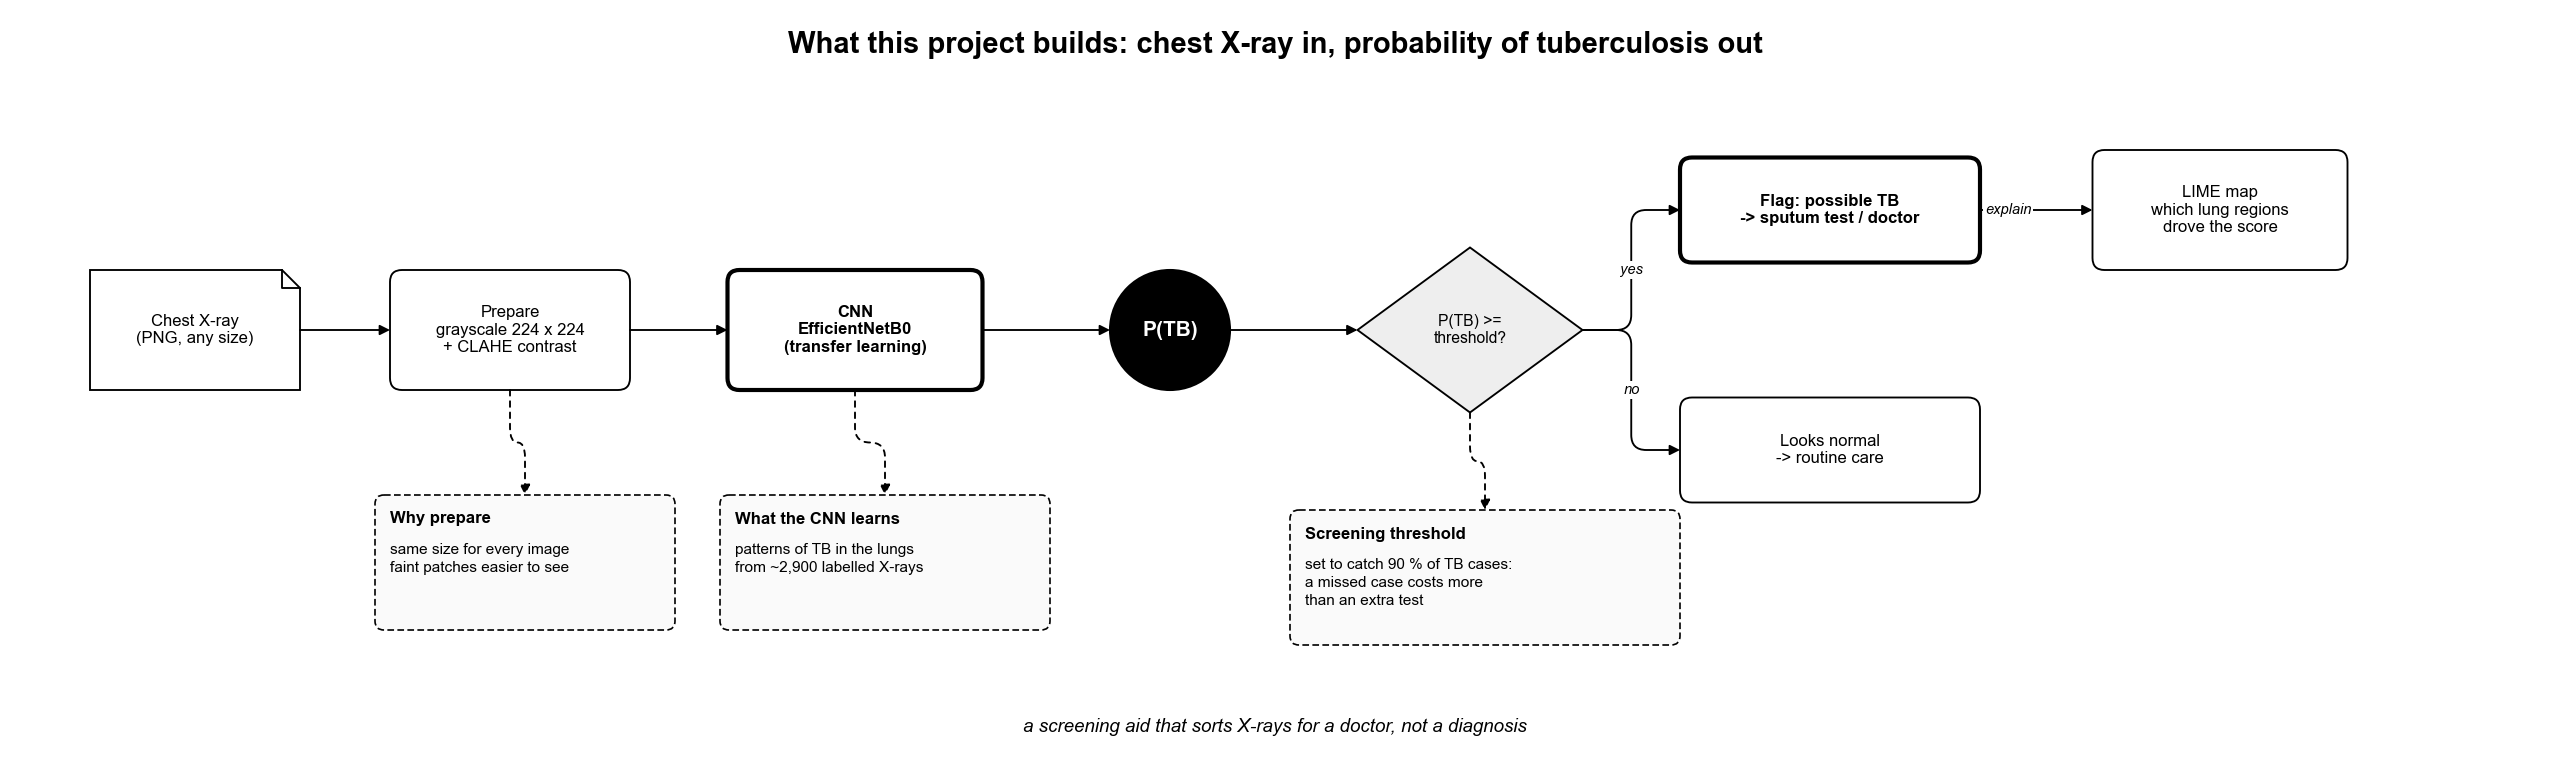

**Aim** → train a CNN that gives every chest X-ray a probability of TB, set the line so it catches 90% of TB cases, and check whether it looks at the lungs or at the hospital the X-ray came from.

**Objectives**
1. Find the shortcuts before the model does: image sources, file properties, near-copies
2. Split honestly, so no near-copy of an X-ray sits on both sides
3. Prepare the images: better contrast and a rough lung mask
4. Fine-tune a pre-trained CNN and pick the threshold for screening (catch TB first)
5. Check where it looks: hide the lungs, then explain single X-rays with LIME

**Where it could help** → many clinics can take an X-ray but have no radiologist on duty. A triage queue puts likely-TB X-rays first and sends them for a sputum test, and the LIME map shows the doctor *where* the model looked.

# [1/13] Setup

Every setting lives in the next cell. Nothing is written to disk unless you turn it on there.

In [ ]:
"""Optional · Add Input → dataset tawsifurrahman/tuberculosis-tb-chest-xray-dataset, Accelerator GPU, Internet On, then Run All.

[1/16] DATA_DIR: dataset folder (searched recursively for Normal/ and Tuberculosis/)
    Default = '/kaggle/input/tuberculosis-tb-chest-xray-dataset'
[2/16] WORK_DIR: folder for the model file
    Default = '/kaggle/working'
[3/16] IMG_SIZE: image size in pixels
    Default = 224
    For example:
        IMG_SIZE = 160
[4/16] ENHANCE: contrast enhancement applied to every image
    Default = 'clahe'
    For example:
        ENHANCE = None
        ENHANCE = 'stretch'
        ENHANCE = 'equalize'
[5/16] HASH_SIZE: difference-hash grid for the near-duplicate search (HASH_SIZE² bits)
    Default = 16
[6/16] DUP_HAMMING: max differing bits for two images to count as near-duplicates
    Default = 10
    For example:
        DUP_HAMMING = 0
[7/16] N_JOBS: threads for reading PNGs
    Default = 4
[8/16] BATCH_SIZE: images per training step
    Default = 32
[9/16] EPOCHS_HEAD: max epochs while the backbone is frozen
    Default = 10
[10/16] EPOCHS_FINE_TUNE: max epochs while fine-tuning
    Default = 8
[11/16] FINE_TUNE_LAST_N: backbone layers unfrozen when fine-tuning
    Default = 20
[12/16] TARGET_SENSITIVITY: share of TB cases the threshold must catch on validation
    Default = 0.90
    For example:
        TARGET_SENSITIVITY = 0.95
[13/16] LIME_SAMPLES: perturbed images per LIME explanation
    Default = 300
    For example:
        LIME_SAMPLES = 1000
[14/16] SAVE_MODEL: save the trained model (+ settings.json for the app)
    Default = False
[15/16] LAUNCH_APP: start the Gradio screening app at the end (public link on Kaggle)
    Default = False
[16/16] DISPLAY_SEED: which images are shown in the example grids (None = a new random sample on every run)
    Default = None
    For example:
        DISPLAY_SEED = 7
"""
DATA_DIR           = '/kaggle/input/tuberculosis-tb-chest-xray-dataset'
WORK_DIR           = '/kaggle/working'
IMG_SIZE           = 224
ENHANCE            = 'clahe'
HASH_SIZE          = 16
DUP_HAMMING        = 10
N_JOBS             = 4
BATCH_SIZE         = 32
EPOCHS_HEAD        = 10
EPOCHS_FINE_TUNE   = 8
FINE_TUNE_LAST_N   = 20
TARGET_SENSITIVITY = 0.90
LIME_SAMPLES       = 300
SAVE_MODEL         = False
LAUNCH_APP         = False

DISPLAY_SEED       = None
SEED               = 42
MODEL_FILE         = f'{WORK_DIR}/tuberculosis_effnetb0.keras'
SETTINGS_FILE      = f'{WORK_DIR}/settings.json'
CLASSES            = ['Normal', 'Tuberculosis']
CLASS_NAMES        = {0: 'normal', 1: 'TB'}
PALETTE            = {0: 'black', 1: 'red'}
PAD                = 30

In [ ]:
%pip install -q lime
import gc
import json
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from scipy import ndimage
from scipy.sparse.csgraph import connected_components
from skimage.measure import label, regionprops
from skimage.segmentation import clear_border, mark_boundaries
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm

from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold

keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')

show_rng = np.random.default_rng(DISPLAY_SEED)   # only decides which example images are displayed


# [2/13] Data

**What I'm trying to do** → list every X-ray and find out where it came from. I don't know yet how mixed the sources are.

In [ ]:
def find_database(*roots):
    """First folder that contains both class sub-folders (Normal/ and Tuberculosis/), searched recursively."""
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for normal in sorted(root.rglob('Normal')):
            if normal.is_dir() and all((normal.parent / cls).is_dir() for cls in CLASSES):
                return normal.parent
    return None


# DATA_DIR first; if the dataset is mounted elsewhere (Kaggle paths differ between setups), search all of /kaggle/input
db_dir = find_database(DATA_DIR, '/kaggle/input')
if db_dir is None:
    mounted = sorted(str(p) for p in Path('/kaggle/input').glob('*/*')) if Path('/kaggle/input').exists() else []
    raise FileNotFoundError(
        f'(!) No folder with {CLASSES} sub-folders under {DATA_DIR} or /kaggle/input.\n'
        f'    Add Input -> Datasets -> tawsifurrahman/tuberculosis-tb-chest-xray-dataset\n'
        f'    Mounted now: {mounted[:20] or "nothing"}')

files_df = pd.DataFrame([{'file': p.name, 'path': str(p), 'class': cls, 'target': target}
                         for target, cls in enumerate(CLASSES)
                         for p in sorted((db_dir / cls).glob('*.png'))])
show_block('Outputs', {'database folder': db_dir, 'files_df': files_df.shape})

In [ ]:
display(files_df.head())

**Question:** How rare is TB in this dataset?

**Answer:** **700 of 4,200 X-rays (16.7%)**, 1 TB image for every 5 normal ones.

That's milder than most medical data, but a model that always says "normal" is still 83% accurate and catches no TB at all. So I judge models by sensitivity, specificity and ROC-AUC ([11/13]), not accuracy.

In [ ]:
counts = files_df['target'].value_counts().sort_index()
display(pd.DataFrame({'images': counts, 'share %': (counts / counts.sum() * 100).round(2)}).rename(index=CLASS_NAMES))

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index.map(CLASS_NAMES), counts.values, color=[PALETTE[0], PALETTE[1]])
for bar, n in zip(bars, counts.values):
    ax.annotate(f'{n:,}\n({n / counts.sum():.1%})', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
ax.set_title('Images per class')
ax.set_ylabel('Images')
ax.margins(y=0.2)
plt.show()

**Question:** Where do the X-rays come from?

The dataset page lists four collections: the NLM sets (Montgomery, USA and Shenzhen, China), a Belarus TB study, the NIAID TB portal and the RSNA pneumonia challenge. Two metadata sheets give each image's source link.

**Answer:** The source gives the class away.

| Source | X-rays | TB |
|---|---|---|
| Belarus TB study | 306 | **100%** |
| Kaggle / RSNA | 3,094 | **0%** (all normal) |
| NLM (Montgomery + Shenzhen) | 800 | 49% |

So a model can score well just by recognising the hospital. I test whether it does in [12/13].

In [ ]:
def read_metadata(cls):
    path = db_dir / f'{cls}.metadata.xlsx'
    if not path.exists():
        return pd.DataFrame()
    meta = pd.read_excel(path)
    meta.columns = [str(col).strip().lower() for col in meta.columns]
    return meta.assign(**{'class': cls})


meta_df = pd.concat([read_metadata(cls) for cls in CLASSES], ignore_index=True)
url_col = next((col for col in meta_df.columns if 'url' in col), None)
show_block('Outputs', {'meta_df': meta_df.shape, 'url column': url_col})

In [ ]:
if url_col:
    meta_df['source'] = meta_df[url_col].astype(str).str.extract(r'https?://(?:www\.)?([^/]+)')[0].fillna('unknown')
    sources = pd.crosstab(meta_df['source'], meta_df['class'])
    sources['TB %'] = (sources['Tuberculosis'] / sources.sum(axis=1) * 100).round(1)
    display(sources.sort_values('Tuberculosis', ascending=False))
else:
    print('(!) no URL column in the metadata sheets → source check skipped')

# [3/13] File properties

**Clue** → the source gives the class away: every Belarus X-ray is TB, every Kaggle / RSNA one is normal.

**I suspect** → each source also saved its files in its own way, so the file alone might tell TB from normal.

**Let's break it down** → read only the PNG headers (no pixels yet) and compare the two classes on 1) colour mode 2) file size. Anything that differs by class is a free shortcut for the CNN.

**Question:** Do normal and TB files differ before anyone looks at a lung?

A CNN uses whatever separates the classes. If TB images were saved in another colour mode or with another compression, the model can score well by recognising the **file**, like a teacher who grades exams by the colour of the paper.

**Answer:** Yes.
- all 308 grayscale (`L`) files are TB; every normal file is RGB
- TB files are smaller and vary much more (median 142 kB, std 67) than normal ones (169 kB, std 14) → different scanners and compression
- loading everything as grayscale removes the colour-mode difference, but not the compression fingerprint

→ My suspicion was right: the file already carries the source. Next lead: does the same fingerprint show up in the pixels? ([6/13])

In [ ]:
def file_props(path):
    with Image.open(path) as image:
        return {'mode': image.mode, 'size': f'{image.size[0]}x{image.size[1]}', 'kB': os.path.getsize(path) / 1024}


with ThreadPoolExecutor(max_workers=N_JOBS) as pool:
    props_df = pd.DataFrame(list(tqdm(pool.map(file_props, files_df['path']), total=len(files_df),
                                      desc='[1.1] Reading PNG headers')))
props_df['class'] = files_df['target'].map(CLASS_NAMES)
show_block('Outputs', {'props_df': props_df.shape})

In [ ]:
for col in ['mode', 'size']:
    table = pd.crosstab(props_df[col], props_df['class'])
    table['TB %'] = (table['TB'] / table.sum(axis=1) * 100).round(1)
    display(table)
display(props_df.groupby('class')['kB'].describe().round(1))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=props_df, x='kB', hue='class', common_norm=False, fill=True, ax=ax,
            palette={'normal': PALETTE[0], 'TB': PALETTE[1]})
ax.set(title='PNG file size per class', xlabel='File size (kB)')
plt.show()

# [4/13] Load images

**Aim** → read every PNG as one grayscale channel at `IMG_SIZE`. About 200 MB in memory at 224 px.

**Question:** How do I turn 4,200 PNGs of 512×512 into model input?

**Answer:** I read each file as a **grayscale** array of shape `(IMG_SIZE, IMG_SIZE)`, values 0 (black) to 255 (white).
- `cv2.IMREAD_GRAYSCALE` → RGB and grayscale files end up the same
- `INTER_AREA` → shrinks by averaging blocks of pixels: fine noise fades, shapes stay

Why only one channel? An X-ray has no colour, so three identical channels would only triple the memory. The copy to 3 channels happens later, batch by batch, because the pre-trained CNN expects RGB.

In [ ]:
def load_gray(path, size=IMG_SIZE):
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)


show_block('Inputs', {'images': f'{len(files_df):,}', 'size': f'{IMG_SIZE}x{IMG_SIZE}', 'threads': N_JOBS})

In [ ]:
with ThreadPoolExecutor(max_workers=N_JOBS) as pool:
    X_raw = np.stack(list(tqdm(pool.map(load_gray, files_df['path']), total=len(files_df), desc='[1.1] Loading PNGs')))
y_all = files_df['target'].to_numpy()
show_block('Outputs', {'X_raw': X_raw.shape, 'y_all': y_all.shape, 'memory': f'{X_raw.nbytes / 1024**2:.0f} MB'})

# [5/13] Near-duplicates and split

**Aim** → find look-alike X-rays, group them, and split by group, so no near-copy of a test image is ever seen in training.

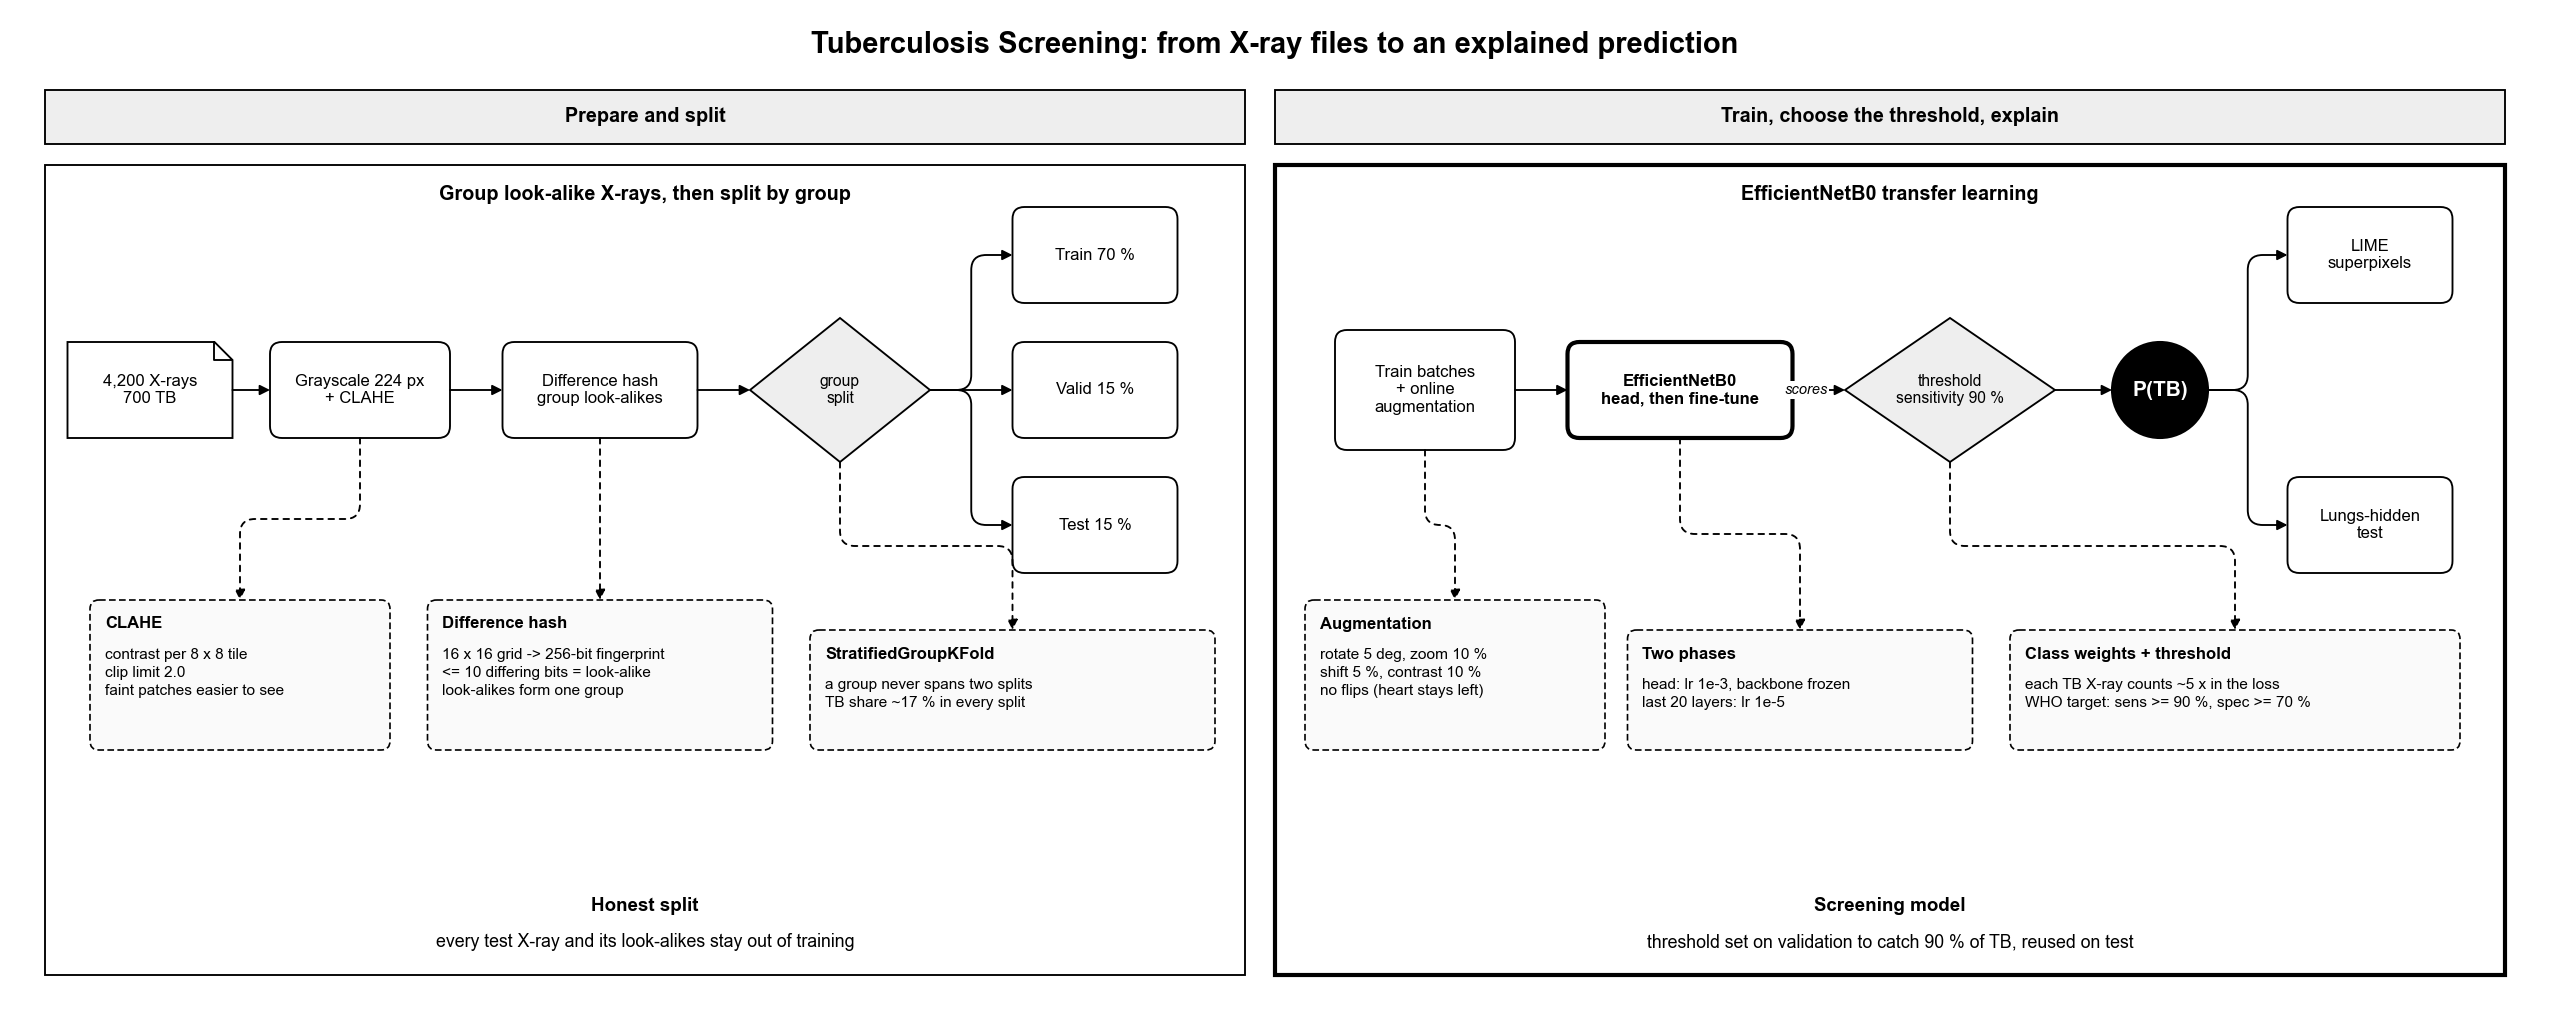

**Question:** Can the same X-ray hide twice in the data?

There are no patient IDs, and public X-ray collections are often re-shared, so the same image (or a resized copy) can show up twice. One copy in training and one in test turns the test into a memory quiz.

**Answer:** Rarely. 20 X-rays have a look-alike (9 groups, the largest has 4), and no group mixes normal and TB. The median X-ray is 32 bits away from its nearest neighbour, far above the limit of 10, so grouping costs nothing and makes sure no copy crosses the split.

**Difference hash (dHash) in one line** → turn every X-ray into a short fingerprint of 256 yes/no answers, then call two X-rays look-alikes when their fingerprints almost match.

**How, in 4 steps**
1. **Shrink** → resize the X-ray to 17 × 16 pixels (`HASH_SIZE` = 16). All the fine detail is gone; only the big light and dark areas stay
2. **Compare neighbours** → for every pixel, ask "is it brighter than the pixel to its right?" → 16 × 16 = 256 yes/no answers (bits). That's the fingerprint. Resizing or making the image a bit brighter barely changes it
3. **Count the differences (Hamming distance)** → put two fingerprints side by side and count the bits that disagree
4. **Group** → two X-rays with at most `DUP_HAMMING` = 10 different bits are linked, and linked X-rays form one **group** (if A ≈ B and B ≈ C, all three are one group)

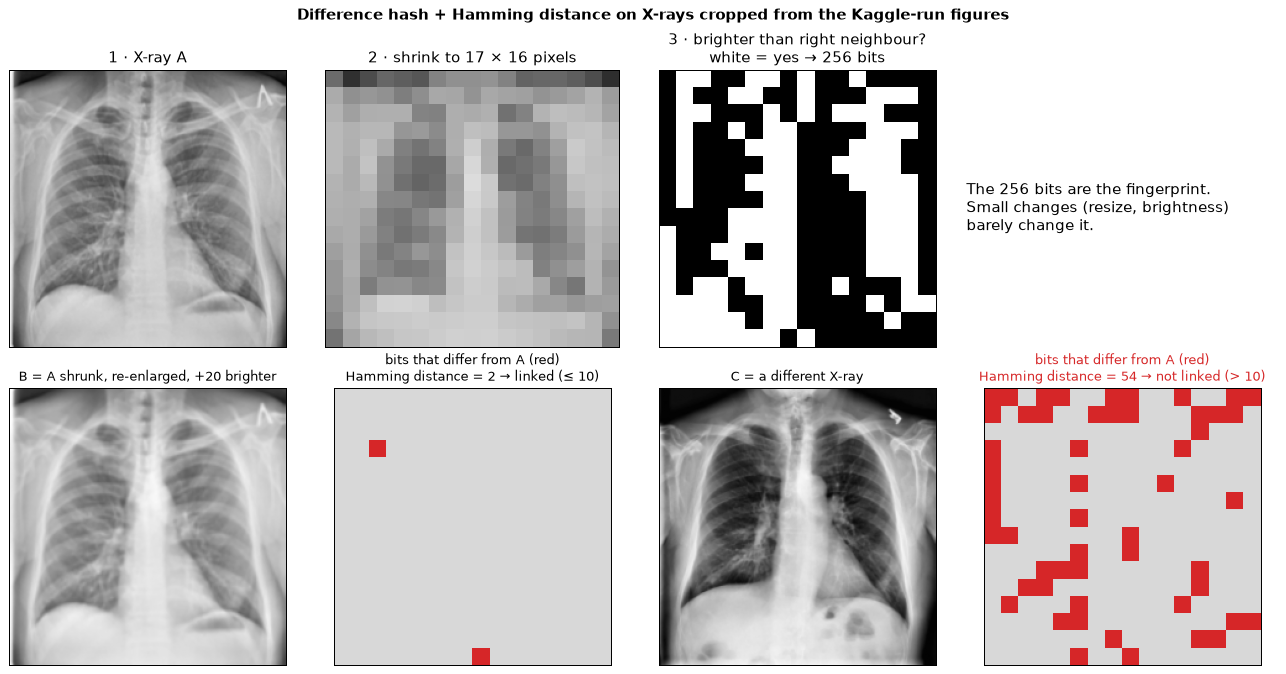

The picture uses X-rays cropped from this notebook's own Kaggle-run figures: a resized, brighter copy is 2 bits away, a different X-ray 54 bits.

**Difference hash + Hamming distance, part by part**

$$a_k = \mathbb{1}\big[\,s(r, c) > s(r, c + 1)\,\big] \qquad d(a, b) = \sum_{k=1}^{256} \mathbb{1}\left[a_k \neq b_k\right] \le 10 \;\Rightarrow\; \text{look-alikes}$$

- $s$ → the X-ray shrunk to 16 rows × 17 columns (`HASH_SIZE` = 16) → only the big light and dark areas survive → resizing or a new compression barely changes it
- $s(r, c) > s(r, c + 1)$ → "is this pixel brighter than its right neighbour?" → it compares neighbours, not grey levels, so a brighter copy gives the same answers
- $a_k$ → bit $k$ of the fingerprint, 16 × 16 = 256 bits per X-ray
- $\mathbb{1}[a_k \neq b_k]$ → 1 when two X-rays disagree on bit $k$
- $d(a, b)$ → the **Hamming distance**, the number of bits that disagree → 0 = same picture, about half (128) = unrelated; in the picture a resized, brighter copy is 2 bits away, a different X-ray 54
- $\le 10$ → `DUP_HAMMING`: at most 10 of 256 bits (4%) may differ → the median X-ray is 32 bits from its nearest neighbour, so the line sits well below ordinary X-rays and well above true copies
- weak spot → the fingerprint only sees big areas in a fixed grid: a heavily cropped, rotated or mirrored copy changes many bits and slips through, and two different chests that look very alike could fall under 10. None of the 9 groups mixes normal and TB, so here neither did visible harm
- In short → count how many of the 256 answers differ. Almost none → the same X-ray; many → two different X-rays

In [ ]:
def dhash_bits(image, hash_size=HASH_SIZE):
    small = cv2.resize(image, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (small[:, 1:] > small[:, :-1]).ravel()


bits     = np.stack([dhash_bits(x) for x in X_raw]).astype(np.float32)
distance = bits @ (1 - bits).T + (1 - bits) @ bits.T
np.fill_diagonal(distance, np.inf)
nearest  = distance.min(axis=1)
n_groups, group = connected_components(distance <= DUP_HAMMING, directed=False)
show_block('Outputs', {'fingerprint bits': bits.shape[1], 'groups': f'{n_groups:,} for {len(X_raw):,} images'})

In [ ]:
group_size  = np.bincount(group)[group]
group_label = pd.Series(y_all).groupby(group).agg(['min', 'max'])
display(pd.DataFrame({'value': {
    'images with a near-duplicate':   f'{(group_size > 1).sum():,}',
    'groups with 2+ images':          f'{(np.bincount(group) > 1).sum():,}',
    'largest group':                  f'{np.bincount(group).max()}',
    'groups mixing normal and TB':    f'{(group_label["min"] != group_label["max"]).sum()}',
    'median nearest distance (bits)': f'{np.median(nearest):.0f} of {bits.shape[1]}',
}}))
if np.bincount(group).max() > 50:
    print(f'(!) one group holds {np.bincount(group).max()} images → DUP_HAMMING is too loose for these X-rays')

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(nearest, bins=np.arange(0, nearest.max() + 2) - 0.5, color='grey')
ax.axvline(DUP_HAMMING + 0.5, color='red', linestyle='--', label=f'DUP_HAMMING = {DUP_HAMMING}')
ax.set(title='Distance from each X-ray to its closest other X-ray', xlabel='Differing bits', ylabel='Images')
ax.legend()
plt.show()

In [ ]:
all_dup_groups = np.flatnonzero(np.bincount(group) > 1)
dup_groups = list(show_rng.choice(all_dup_groups, min(6, len(all_dup_groups)), replace=False)) if len(all_dup_groups) else []
if dup_groups:
    fig, axes = plt.subplots(len(dup_groups), 2, figsize=(7, 3.5 * len(dup_groups)), squeeze=False)
    for row, g in enumerate(dup_groups):
        i, j = np.flatnonzero(group == g)[:2]
        for ax, k in zip(axes[row], [i, j]):
            ax.imshow(X_raw[k], cmap='gray')
            ax.set_title(f"{files_df.loc[k, 'file']}  d = {distance[i, j]:.0f}", fontsize=9, color=PALETTE[y_all[k]])
            ax.axis('off')
    plt.suptitle('Near-duplicate pairs', fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('No near-duplicates at this threshold')

**Question:** How do I get honest validation and test sets?

**Answer:** Split by group with `StratifiedGroupKFold`: each group of look-alikes lands in one split only, and every split keeps about the same share of TB.

| Split | X-rays | TB share |
|---|---|---|
| train | 3,004 | ~16.6% |
| validation | 599 | ~16.6% |
| test | 597 | ~16.6% (99 TB) |

**Grouped split in one line** → shuffle whole groups, not single X-rays, so look-alikes always travel together.

**How the split works**
1. Every X-ray carries its group number from the step above (most groups have just 1 X-ray)
2. Shuffle the **groups**, not the images
3. Give whole groups to test (about 1/7), then to validation (about 1/6 of the rest), keeping the TB share about the same in each split

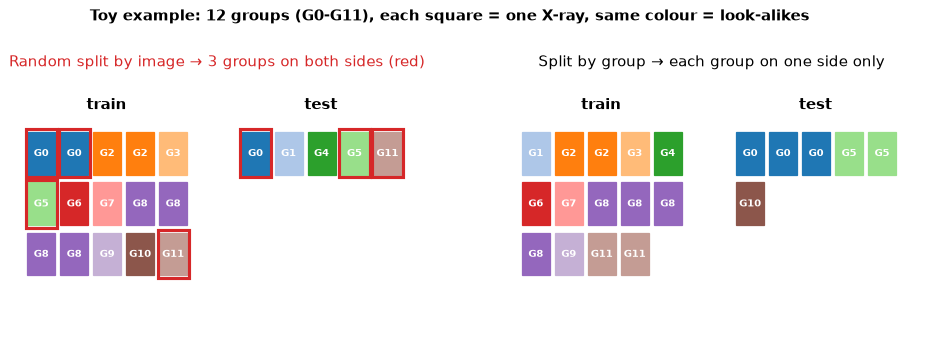

The picture is a toy with 12 groups: a random split by image puts 3 of them on both sides. If a group ever shows up in two splits here, the notebook stops with an error.

In [ ]:
def grouped_split(groups, y, n_splits, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups))


trainval_pos, test_idx = grouped_split(group, y_all, n_splits=7)
train_pos, val_pos     = grouped_split(group[trainval_pos], y_all[trainval_pos], n_splits=6)
train_idx, val_idx     = trainval_pos[train_pos], trainval_pos[val_pos]
splits                 = {'train': train_idx, 'val': val_idx, 'test': test_idx}

split_groups = {name: set(group[idx]) for name, idx in splits.items()}
shared       = (split_groups['train'] & split_groups['val']) | (split_groups['train'] & split_groups['test']) | (split_groups['val'] & split_groups['test'])
assert not shared, f'(!) {len(shared)} duplicate groups appear in more than one split'

display(pd.DataFrame({name: {'images': len(idx), 'TB': int(y_all[idx].sum()), 'TB %': round(y_all[idx].mean() * 100, 1)}
                      for name, idx in splits.items()}).T.astype({'images': int, 'TB': int}))

# [6/13] Image EDA

**Clue** → so far everything that points at the class sits outside the lungs: the source ([2/13]), the colour mode and the file size ([3/13]).

**I suspect** → the pixels carry the same fingerprint, so TB and normal X-rays may differ around the lungs as much as inside them.

**Question** → where do normal and TB X-rays differ: inside the lungs, or around them?

**Let's break it down** → 1) look at random X-rays of both classes 2) average each class and subtract the two averages 3) compare brightness, contrast and black borders

**Question:** What do the X-rays look like?

**What to look for** → TB shows up as hazy white patches (consolidation), small nodules or holes (cavities), often in the **upper** lungs. Also look outside the lungs: text markers ("L", "R"), black borders, rotated or cropped images. Those come from how the X-ray was taken (**acquisition**). If one class has more of them, the CNN may learn them instead of the disease.

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(17.6, 10))
for cls, rows in [(0, axes[:2]), (1, axes[2:])]:
    for ax, i in zip(rows.ravel(), show_rng.choice(np.flatnonzero(y_all == cls), rows.size, replace=False)):
        ax.imshow(X_raw[i], cmap='gray')
        ax.set_title(f"{CLASS_NAMES[cls]}\n{files_df.loc[i, 'file']}", fontsize=8, color=PALETTE[cls])
        ax.axis('off')
plt.suptitle('Random normal (top two rows) and TB (bottom two rows) X-rays', fontweight='bold')
plt.tight_layout()
plt.show()

**Question:** What does the *average* normal and TB X-ray look like?

$$\bar I_c(x, y) = \frac{1}{n_c} \sum_{i \in c} I_i(x, y)$$
- $\bar I_c(x, y)$ → **mean image** of class $c$: the average brightness at pixel $(x, y)$
- $I_i(x, y)$ → brightness of X-ray $i$ at that pixel
- $n_c$ → number of X-rays in class $c$
- In short → lay all X-rays of one class on top of each other and average every pixel. What most X-rays share stays sharp; what changes from one X-ray to the next fades into a blur

The difference map $\bar I_{TB} - \bar I_{normal}$ shows **where** the classes differ on average: red = brighter in TB, blue = darker.

**Answer:** Both kinds of difference are there.
- inside the lungs the TB average is brighter (red) → denser tissue, the disease signal
- the strongest differences sit at the top corners and borders (up to +60 grey levels) → how each source took its X-rays, a shortcut the CNN can use

→ My suspicion holds: the biggest differences sit around the lungs, not in them. That's why I build a lung mask in [8/13], to test the model with the lungs hidden in [12/13].

In [ ]:
mean_img = {cls: X_raw[y_all == cls].mean(axis=0) for cls in [0, 1]}
diff     = mean_img[1] - mean_img[0]
limit    = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, cls in zip(axes[:2], [0, 1]):
    ax.imshow(mean_img[cls], cmap='gray')
    ax.set_title(f'Mean {CLASS_NAMES[cls]} X-ray (n = {(y_all == cls).sum():,})')
im = axes[2].imshow(diff, cmap='coolwarm', vmin=-limit, vmax=limit)
axes[2].set_title('Mean TB − mean normal')
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**I'm curious** → if the corners differ by up to +60 grey levels, does the whole X-ray differ too?

**Question:** Do the classes differ in overall brightness, contrast or black borders?
- **Brightness** → mean pixel value of one X-ray
- **Contrast (std)** → how far the pixel values spread from that mean
- **Black frame %** → share of near-black pixels (< 10) in the outer 8% frame: scanned films and some machines leave black borders

**Answer:** Not in brightness, as I half expected: it is the same (median 125 vs 126). But normal X-rays have more contrast (64 vs 53) and twice the black frame (17% vs 8%) → one more acquisition fingerprint.

In [ ]:
def frame_black_share(image, frame=0.08, level=10):
    k      = max(1, int(image.shape[0] * frame))
    border = np.concatenate([image[:k].ravel(), image[-k:].ravel(), image[:, :k].ravel(), image[:, -k:].ravel()])
    return (border < level).mean() * 100


stats_df = pd.DataFrame({
    'brightness':     X_raw.reshape(len(X_raw), -1).mean(axis=1),
    'contrast (std)': X_raw.reshape(len(X_raw), -1).std(axis=1),
    'black frame %':  [frame_black_share(x) for x in X_raw],
    'class':          pd.Series(y_all).map(CLASS_NAMES),
})
display(stats_df.groupby('class').median().round(1))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['brightness', 'contrast (std)', 'black frame %']):
    sns.kdeplot(data=stats_df, x=col, hue='class', common_norm=False, fill=True, ax=ax,
                palette={'normal': PALETTE[0], 'TB': PALETTE[1]}, warn_singular=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# [7/13] Contrast enhancement

**Aim** → many X-rays look washed out. I compare three ways to spread their grey levels, and `ENHANCE` applies one to every image.

**Question:** Can I make faint patches easier to see?

**Answer:** Yes. All three methods spread the grey levels, but in different ways:

| Method | What it does | Catch |
|---|---|---|
| stretching | rescales the grey levels to fill 0-255 | changes little if the image already has a few very dark or bright pixels |
| equalization | spreads them evenly over the whole image | can blow out the background |
| CLAHE | does the same per small tile, with a cap | ribs and lung texture stay visible → **default** |

The earlier version of this project found plain equalization the best of the three with its small CNN; set `ENHANCE = 'equalize'` to compare. Each method works on one image at a time and learns nothing from other images, so it can run before the split without leaking.

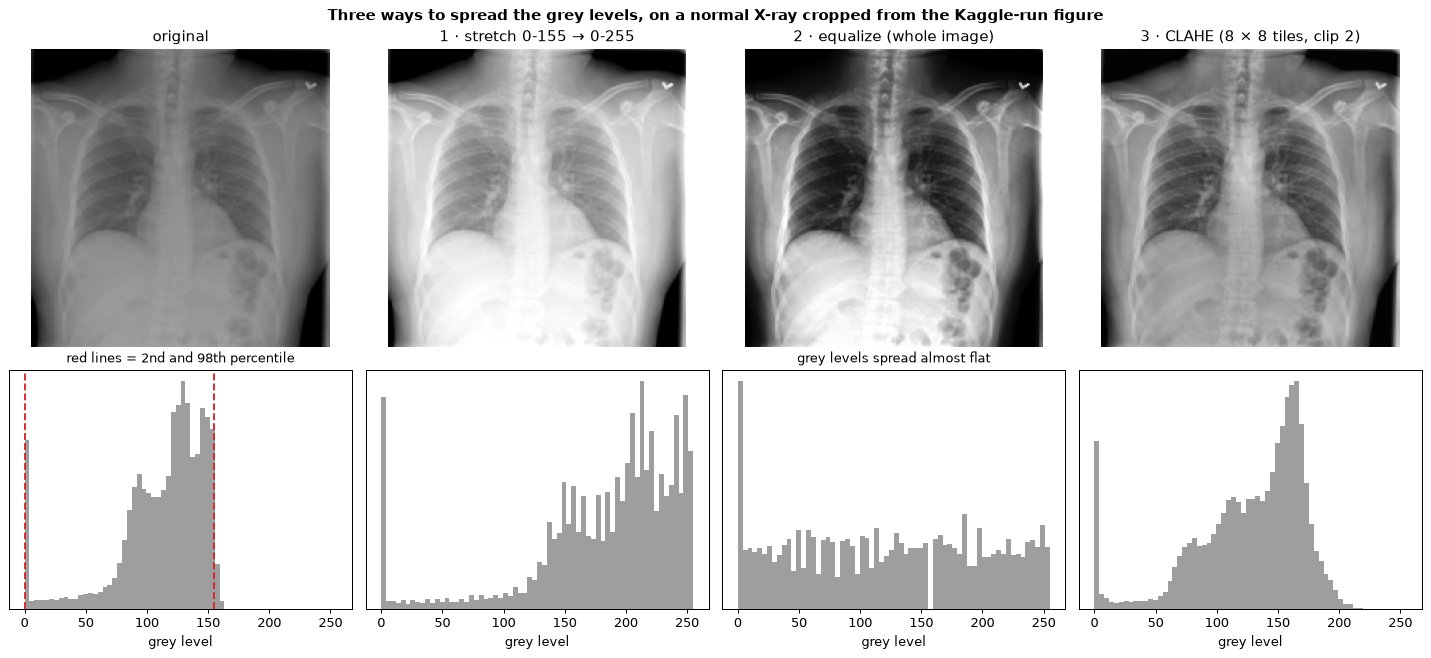

**1. Contrast stretching in one line** → take the image's darkest and brightest grey (ignoring a few extreme pixels) and pull them out to pure black and pure white.

1. Find the 2nd and 98th percentile ($p_2$, $p_{98}$): the "darkest" and "brightest" grey if I skip the 2% most extreme pixels on each side
2. Map $p_2$ → 0 and $p_{98}$ → 255, everything in between on a straight line
3. Clip what falls outside to 0 or 255

$$I'(x, y) = 255 \cdot \frac{I(x, y) - p_{2}}{p_{98} - p_{2}}$$
- $I(x, y)$ → original brightness of a pixel, $I'$ → new brightness, clipped to 0-255
- $p_2, p_{98}$ → the image's 2nd and 98th percentile
- In short → the same picture, with its grey range pulled out to fill black to white. The order of the greys never changes

**2. Histogram equalization in one line** → give every grey level a new value by its rank, so the greys end up spread evenly from black to white.

1. Sort all pixels by brightness
2. For each grey level, find the share of pixels that are as dark or darker (the CDF)
3. That share becomes the new brightness: a pixel brighter than 70% of the image becomes $0.7 \times 255 \approx 179$

$$I'(x, y) = \operatorname{round}\big(255 \cdot \text{CDF}(I(x, y))\big)$$
- $\text{CDF}(v)$ → share of the image's pixels that are at most $v$
- In short → each pixel gets a new brightness from its rank in the image. Darkest pixel → black, brightest → white, and the histogram ends up almost flat

**3. CLAHE in one line** (Contrast Limited Adaptive Histogram Equalization) → equalization done separately in small tiles, with a cap so flat areas don't turn into noise.

1. Cut the X-ray into an 8 × 8 grid of tiles
2. Equalize each tile on its own, so a dark lung and a bright spine each get their own contrast
3. **Clip limit** (2.0) → no grey level may hold more than its share; the extra is spread over the others, so a flat area doesn't get its tiny noise blown up
4. Blend neighbouring tiles at their edges, so no grid lines show

In [ ]:
def stretch(image, low=2, high=98):
    p_low, p_high = np.percentile(image, (low, high))
    return np.clip((image.astype(np.float32) - p_low) * 255.0 / max(p_high - p_low, 1), 0, 255).astype(np.uint8)


def equalize(image):
    return cv2.equalizeHist(image)


def clahe(image, clip=2.0, tiles=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(image)


ENHANCERS = {None: lambda image: image, 'stretch': stretch, 'equalize': equalize, 'clahe': clahe}
assert ENHANCE in ENHANCERS, f'(!) ENHANCE must be one of {list(ENHANCERS)}'

In [ ]:
examples = [show_rng.choice(np.flatnonzero(y_all == 0)), *show_rng.choice(np.flatnonzero(y_all == 1), 2, replace=False)]
methods  = [('original', None), ('stretch', 'stretch'), ('equalize', 'equalize'), ('clahe', 'clahe')]

fig, axes = plt.subplots(2 * len(examples), 4, figsize=(16, 7.5 * len(examples)))
for row, i in enumerate(examples):
    for col, (name, key) in enumerate(methods):
        out = ENHANCERS[key](X_raw[i])
        axes[2 * row, col].imshow(out, cmap='gray', vmin=0, vmax=255)
        axes[2 * row, col].set_title(f'{CLASS_NAMES[y_all[i]]} · {name}', color=PALETTE[y_all[i]])
        axes[2 * row, col].axis('off')
        axes[2 * row + 1, col].hist(out.ravel(), bins=64, range=(0, 255), color='grey')
        axes[2 * row + 1, col].set_yticks([])
plt.suptitle('Contrast enhancement and the grey-level histogram it produces', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
X_all = np.stack([ENHANCERS[ENHANCE](x) for x in tqdm(X_raw, desc=f'[1.1] Enhancing ({ENHANCE})')])
show_block('Outputs', {'X_all': X_all.shape, 'enhancement': ENHANCE})

# [8/13] Lung mask

**Clue** → the mean images in [6/13] differ most at the top corners and borders (up to +60 grey levels), outside the lungs.

**Aim** → find the lungs with classic image processing (no trained model), so I can later hide them and test whether the CNN finds TB inside or outside them ([12/13]).

**Question:** Can I find the lungs without a trained segmentation model?

**Answer:** Well enough for a shortcut test. The median lung area is 24% of the image for normal X-rays and 18% for TB (bright patches shrink the mask). 351 masks (8%) fall outside 5-60% of the image and are rough.

**Lung mask in one line** → on an X-ray, air is dark and bone and tissue are bright, so the lungs are the two big dark areas inside the body.

**How, in 5 steps**
1. **CLAHE** → evens out the contrast so both lungs come out equally dark
2. **Otsu threshold** → picks the grey level $t$ that splits the pixels into "dark" and "bright" as cleanly as possible; dark → white in the mask
3. **Clear border** → dark areas touching the image edge are air **outside** the body → removed
4. **Two largest areas** → left and right lung; smaller dark spots (stomach gas, noise) are dropped
5. **Closing, hole filling, dilation** → seal the gaps left by ribs and vessels, then grow the mask a little so the lung edges are inside it

**Otsu threshold in one line** → try every grey level as the dividing line, and keep the one where the dark side and the bright side are most different from each other.

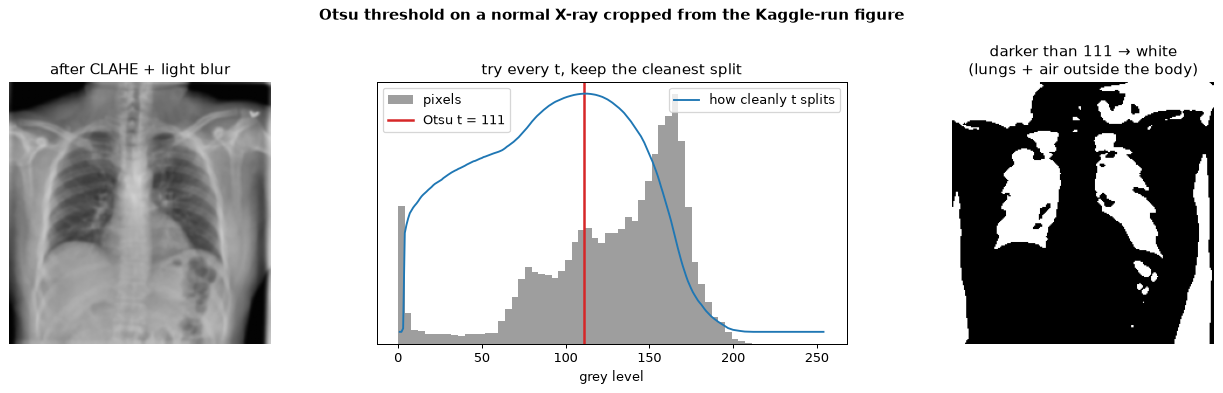

$$t^* = \underset{t}{\arg\max}\; \omega_0(t)\,\omega_1(t)\,\big[\mu_0(t) - \mu_1(t)\big]^2$$
- $t$ → a candidate grey level, from 0 to 255; $t^*$ → the one that wins
- $\omega_0, \omega_1$ → share of pixels darker / brighter than $t$
- $\mu_0, \mu_1$ → average brightness of each side
- In short → a good line leaves two big groups whose average brightness is far apart. Otsu tries every line and keeps the best (the peak of the blue curve)

The full 5 steps are shown on real X-rays two cells down.

In [ ]:
def odd_kernel(fraction, size):
    k = max(3, int(round(size * fraction)) | 1)
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def lung_mask_steps(image, keep=2):
    size       = image.shape[0]
    equalized  = clahe(image)
    blurred    = cv2.GaussianBlur(equalized, (5, 5), 0)
    _, dark    = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    inside     = clear_border(dark > 0)
    labels     = label(inside)
    largest    = sorted(regionprops(labels), key=lambda r: r.area, reverse=True)[:keep]
    lungs      = np.isin(labels, [r.label for r in largest]).astype(np.uint8)
    closed     = cv2.morphologyEx(lungs, cv2.MORPH_CLOSE, odd_kernel(0.07, size))
    filled     = ndimage.binary_fill_holes(closed).astype(np.uint8)
    final      = cv2.dilate(filled, odd_kernel(0.03, size)).astype(bool)
    return {'1 CLAHE': equalized, '2 Otsu (dark = white)': dark, '3 clear border': inside,
            '4 two largest': lungs, '5 final mask': final}


def lung_mask(image):
    return lung_mask_steps(image)['5 final mask']

In [ ]:
shown = [*show_rng.choice(np.flatnonzero(y_all == 0), 2, replace=False), *show_rng.choice(np.flatnonzero(y_all == 1), 2, replace=False)]

fig, axes = plt.subplots(len(shown), 7, figsize=(24, 3.8 * len(shown)))
for row, i in enumerate(shown):
    steps = lung_mask_steps(X_raw[i])
    axes[row, 0].imshow(X_raw[i], cmap='gray')
    axes[row, 0].set_title(f'original · {CLASS_NAMES[y_all[i]]}', color=PALETTE[y_all[i]])
    for col, (name, img) in enumerate(steps.items(), start=1):
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(name)
    axes[row, 6].imshow(X_raw[i], cmap='gray')
    axes[row, 6].contour(steps['5 final mask'], colors='yellow', linewidths=1.5)
    axes[row, 6].set_title('overlay')
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle('Lung mask, step by step', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
masks    = np.stack([lung_mask(x) for x in tqdm(X_raw, desc='[1.1] Lung masks')])
coverage = masks.reshape(len(masks), -1).mean(axis=1) * 100
failed   = (coverage < 5) | (coverage > 60)
display(pd.DataFrame({'median lung area %': pd.Series(coverage).groupby(y_all).median().round(1),
                      'masks outside 5-60 %': pd.Series(failed).groupby(y_all).sum()}).rename(index=CLASS_NAMES))

In [ ]:
del X_raw, bits, distance
gc.collect()
X_tr, y_tr   = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_te, y_te   = X_all[test_idx], y_all[test_idx]
show_block('Outputs', {
    'X_tr':  f'{X_tr.shape}  classes {np.bincount(y_tr)}',
    'X_val': f'{X_val.shape}  classes {np.bincount(y_val)}',
    'X_te':  f'{X_te.shape}  classes {np.bincount(y_te)}',
})

# [9/13] Imbalance and augmentation

**Aim** → stop the CNN from ignoring TB, without making copies of images before or after the split.

**Question:** Training has about 5 normal X-rays per TB X-ray. How do I stop the CNN from ignoring TB?

**Answer:** Two fixes, neither of which makes copies of images:
1. **Class weights** → each TB X-ray counts about 5× a normal one in the loss (normal 0.60, TB 2.99; exact values printed below)
2. **Online augmentation** → every epoch, every training X-ray is shown slightly changed, inside the model, so validation and test never contain a copy of a training image

**1. Class weights in one line** → every TB X-ray counts more in the loss, so the two classes end up with the same total say.

$$w_c = \frac{n}{2\,n_c}$$
- $w_c$ → weight of every image of class $c$ in the loss
- $n$ → all training images, $n_c$ → training images of class $c$
- $2$ → number of classes, so a perfectly balanced set gets $w = 1$ for both
- In short → the rarer the class, the bigger its weight. With 5 normal X-rays per TB X-ray, each TB X-ray counts 5×, so both classes matter equally in total

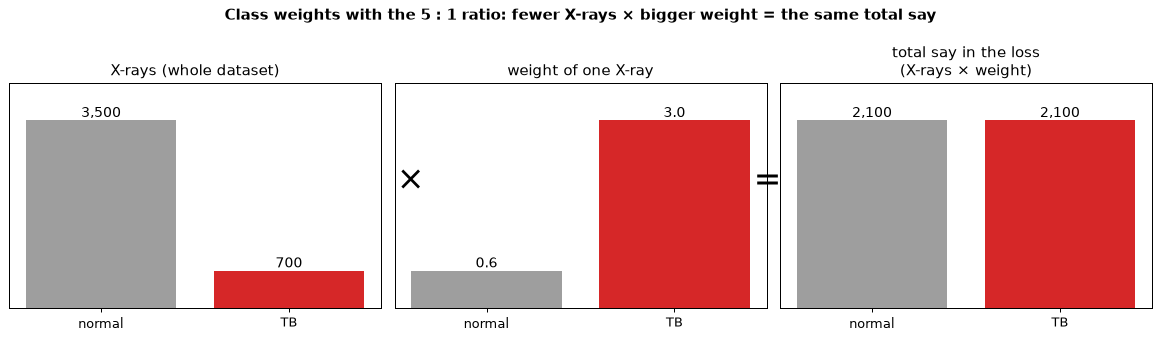

**2. Online augmentation in one line** → small random changes, a new set each epoch, that a real X-ray could also have.

| Layer | Range | Why it is safe for X-rays |
|---|---|---|
| `RandomRotation` | ±5° | patients never stand perfectly straight |
| `RandomZoom` | ±10% | distance to the detector varies |
| `RandomTranslation` | ±5% | the chest is never exactly centred |
| `RandomContrast` | ±10% | exposure varies between machines |

**How it works**
1. A training batch goes into the model
2. The augmentation layers pick a random angle, zoom, shift and contrast for each X-ray
3. The CNN learns from the changed X-rays; next epoch it gets new random changes
4. At prediction time the layers do nothing, so validation, test and the app see the real X-ray

**Not used: flips** → a mirrored X-ray puts the heart on the right, which almost no patient has. The model would learn from impossible pictures.

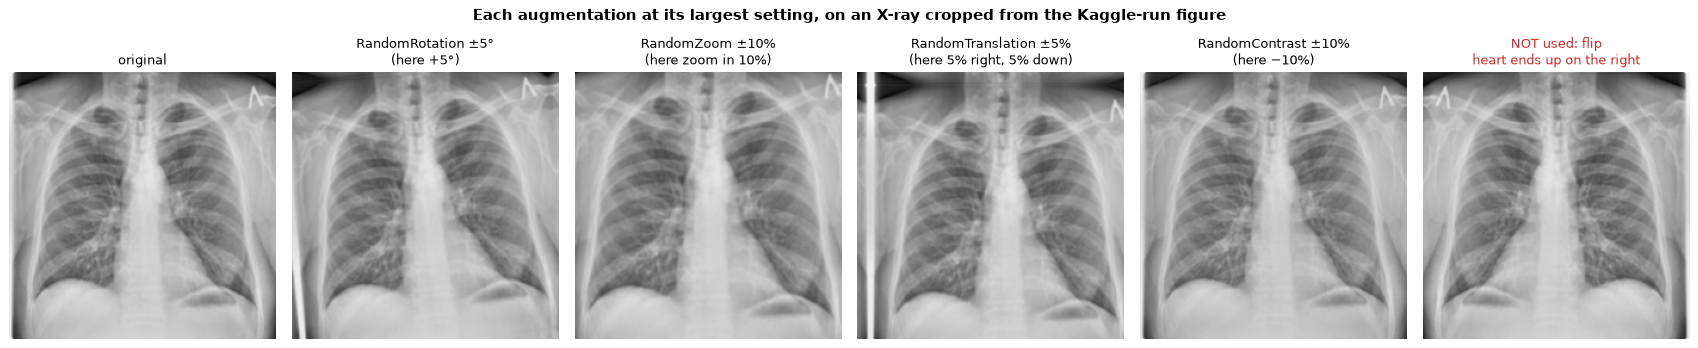

In [ ]:
counts       = np.bincount(y_tr)
class_weight = {cls: len(y_tr) / (2 * n) for cls, n in enumerate(counts)}
display(pd.DataFrame({'images': counts, 'weight': [round(w, 3) for w in class_weight.values()]}, index=['normal', 'TB']))

In [ ]:
augment = keras.Sequential([layers.RandomRotation(5 / 360),
                            layers.RandomZoom(0.1),
                            layers.RandomTranslation(0.05, 0.05),
                            layers.RandomContrast(0.1)], name='online_augmentation')

sample = X_tr[show_rng.choice(np.flatnonzero(y_tr == 1))].astype('float32')[None, :, :, None]
fig, axes = plt.subplots(1, 8, figsize=(24, 3.4))
axes[0].imshow(sample[0, :, :, 0], cmap='gray', vmin=0, vmax=255)
axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(np.clip(augment(sample, training=True)[0, :, :, 0], 0, 255), cmap='gray', vmin=0, vmax=255)
    ax.set_title('augmented')
for ax in axes:
    ax.axis('off')
plt.suptitle('One random training X-ray, seven epochs of augmentation', fontweight='bold')
plt.tight_layout()
plt.show()

# [10/13] Modeling

**Clue** → the ground is ready: no near-copy crosses the split, every X-ray is enhanced with CLAHE, and each TB X-ray weighs 2.99 in the loss against 0.60 for a normal one.

**I'm curious** → is that enough for a CNN that has only seen everyday photos to learn chest X-rays from ~2,900 training images?

**Let's break it down** → 1) reuse a pre-trained EfficientNetB0 2) turn its score into a probability (sigmoid) 3) train it with the weighted loss 4) keep the weights with the best validation AUC

**Answer:** Yes. Training only the new head reaches a best validation AUC of 0.9938; fine-tuning the last 20 backbone layers lifts it to 0.9960 (curves below).

**1. Transfer learning** → EfficientNetB0 already learned edges, textures and shapes from 1.2M ImageNet photos. I keep that visual vocabulary and train a small new head on top, like hiring an experienced photographer and teaching them radiology instead of training someone who has never seen a picture.

**How, in 2 phases**
1. **Head** → keep the whole backbone frozen and train only the new head, so the random new layer can't damage what the backbone knows
2. **Fine-tune** → unfreeze the last 20 backbone layers and keep training with a 100× smaller learning rate, so they adjust a little to X-rays

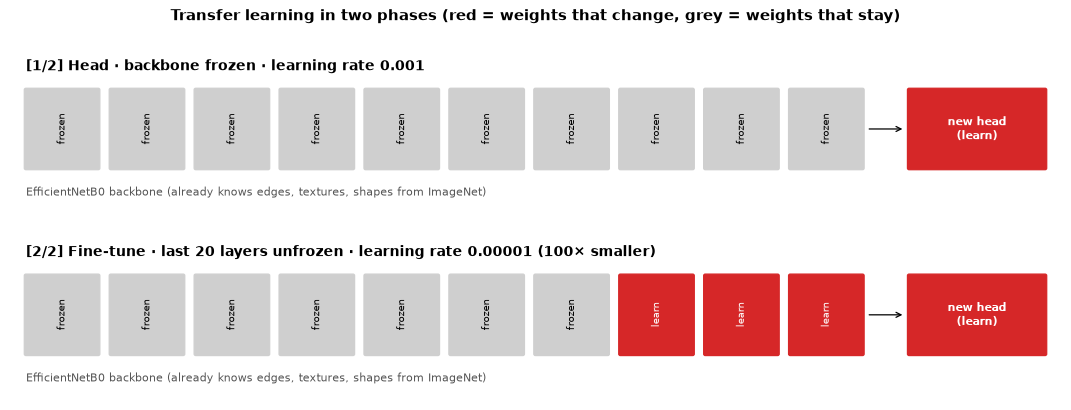

**2. Sigmoid + weighted binary cross-entropy: what training minimises, part by part**

$$p = \sigma(z) = \frac{1}{1 + e^{-z}} \qquad L = -\,w_y\big[\,y \log p + (1 - y) \log (1 - p)\,\big]$$

- $z$ → the **raw score** → the head adds up the 1,280 pooled feature maps, each times its own weight, plus a bias (the 1,281 head parameters) → one number of any size, not yet a probability
- $\sigma(z) = \frac{1}{1 + e^{-z}}$ → the **sigmoid** → squashes $z$ into $(0, 1)$: $z = 0$ → 0.5, very negative → close to 0 (normal), very positive → close to 1 (TB). The screening threshold 0.881 from [11/13] means "say TB only when $z > 2.0$"
- $y \log p$ → switched on only for a TB X-ray ($y = 1$) → cost $-\log p$: says 90% → 0.11, says 40% → 0.92, says 1% → 4.61 → the log punishes "wrong and sure" far more than "unsure"
- $(1 - y) \log (1 - p)$ → the mirror image, switched on only for a normal X-ray → the cost grows as $p$ moves towards 1, a confident false alarm
- $w_y$ → the **class weight** from [9/13]: 2.99 for TB, 0.60 for normal → the same doubt ($p = 0.5$) costs 2.07 on a TB X-ray and 0.42 on a normal one, 5× more → with 5 normal X-rays per TB one, both classes pull equally hard. Side effect: the weights push P(TB) above the real share of TB, so P(TB) is a score for ranking, not a calibrated chance → I pick the line on validation in [11/13], and calibration is a next step
- averaged over each batch of 32 → every X-ray counts once, times its weight → assumes the labels are right: one mislabelled TB X-ray scored at 1% costs 4.61 × 2.99 ≈ 13.8 and pulls hard on the weights
- what the loss does **not** see → it rewards getting $y$ right, not *why*. A border strip or a bright corner that separates the classes lowers $L$ just as well as a lesion → nothing in this formula stops the source shortcut from [2/13]-[6/13]; [12/13] checks whether the model took it
- In short → the network's score becomes a probability between 0 and 1, and training keeps shrinking the error, where doubting a real TB X-ray costs 5× more than the same doubt on a normal one

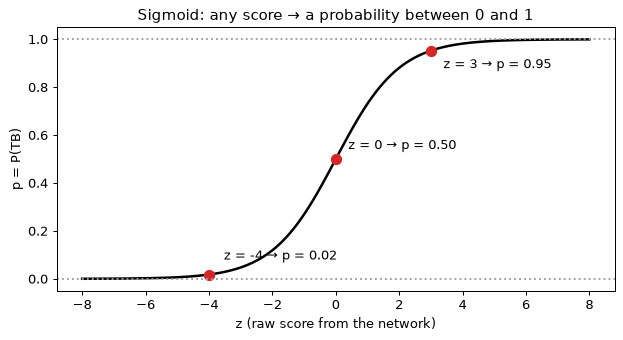

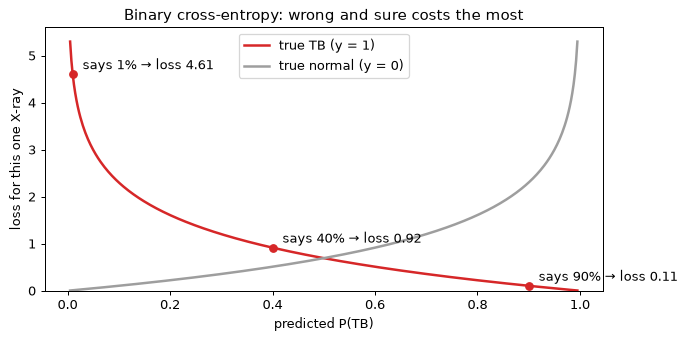

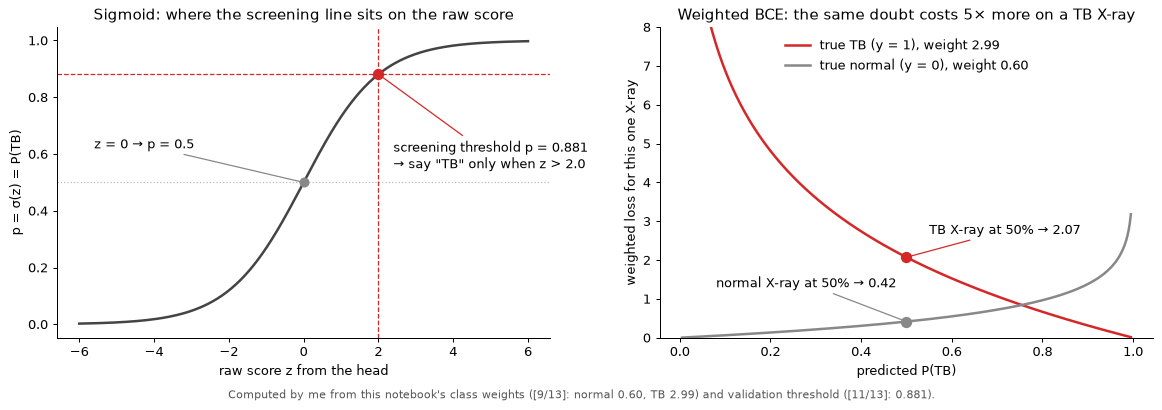

*The last picture is computed by me from this notebook's class weights ([9/13]) and validation threshold ([11/13]).*

**4. How I train it**
- **[1/2] Head** → backbone frozen, learning rate $10^{-3}$
- **[2/2] Fine-tune** → last `FINE_TUNE_LAST_N` backbone layers unfrozen, learning rate $10^{-5}$: 100× smaller, so it adjusts rather than overwrites what was learned
- **Grayscale → RGB** → the one channel is copied three times per batch, because the backbone expects colour input
- **Frozen BatchNorm** → the backbone keeps its ImageNet statistics, also while fine-tuning
- **Mixed precision** on GPU → float16 math, float32 output: faster, less memory

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
else:
    print('(!) No GPU found → training will be slow. Kaggle: Settings → Accelerator → GPU')
show_block('Outputs', {'TensorFlow': tf.__version__, 'GPUs': len(gpus),
                       'precision policy': keras.mixed_precision.global_policy().name})

In [ ]:
def to_rgb(image, label):
    return tf.image.grayscale_to_rgb(tf.cast(image, tf.float32)[..., None]), label


def make_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype('float32')))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(to_rgb, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_tr, y_tr, training=True)
val_ds   = make_dataset(X_val, y_val, training=False)
show_block('Outputs', {'train batches': len(train_ds), 'val batches': len(val_ds)})

In [ ]:
def build_model(img_size=IMG_SIZE, dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(img_size, img_size, 3))
    base.trainable = False

    inputs  = keras.Input(shape=(img_size, img_size, 3))
    x       = augment(inputs)
    x       = base(x, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    return keras.Model(inputs, outputs, name='tuberculosis_effnetb0'), base


def make_metrics():
    return [keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]


def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, min_lr=1e-7)]

In [ ]:
model, base_model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=make_metrics())
show_block('Outputs', {'parameters': f'{model.count_params():,}',
                       'trainable':  f'{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}'})

**5. Inside EfficientNetB0**

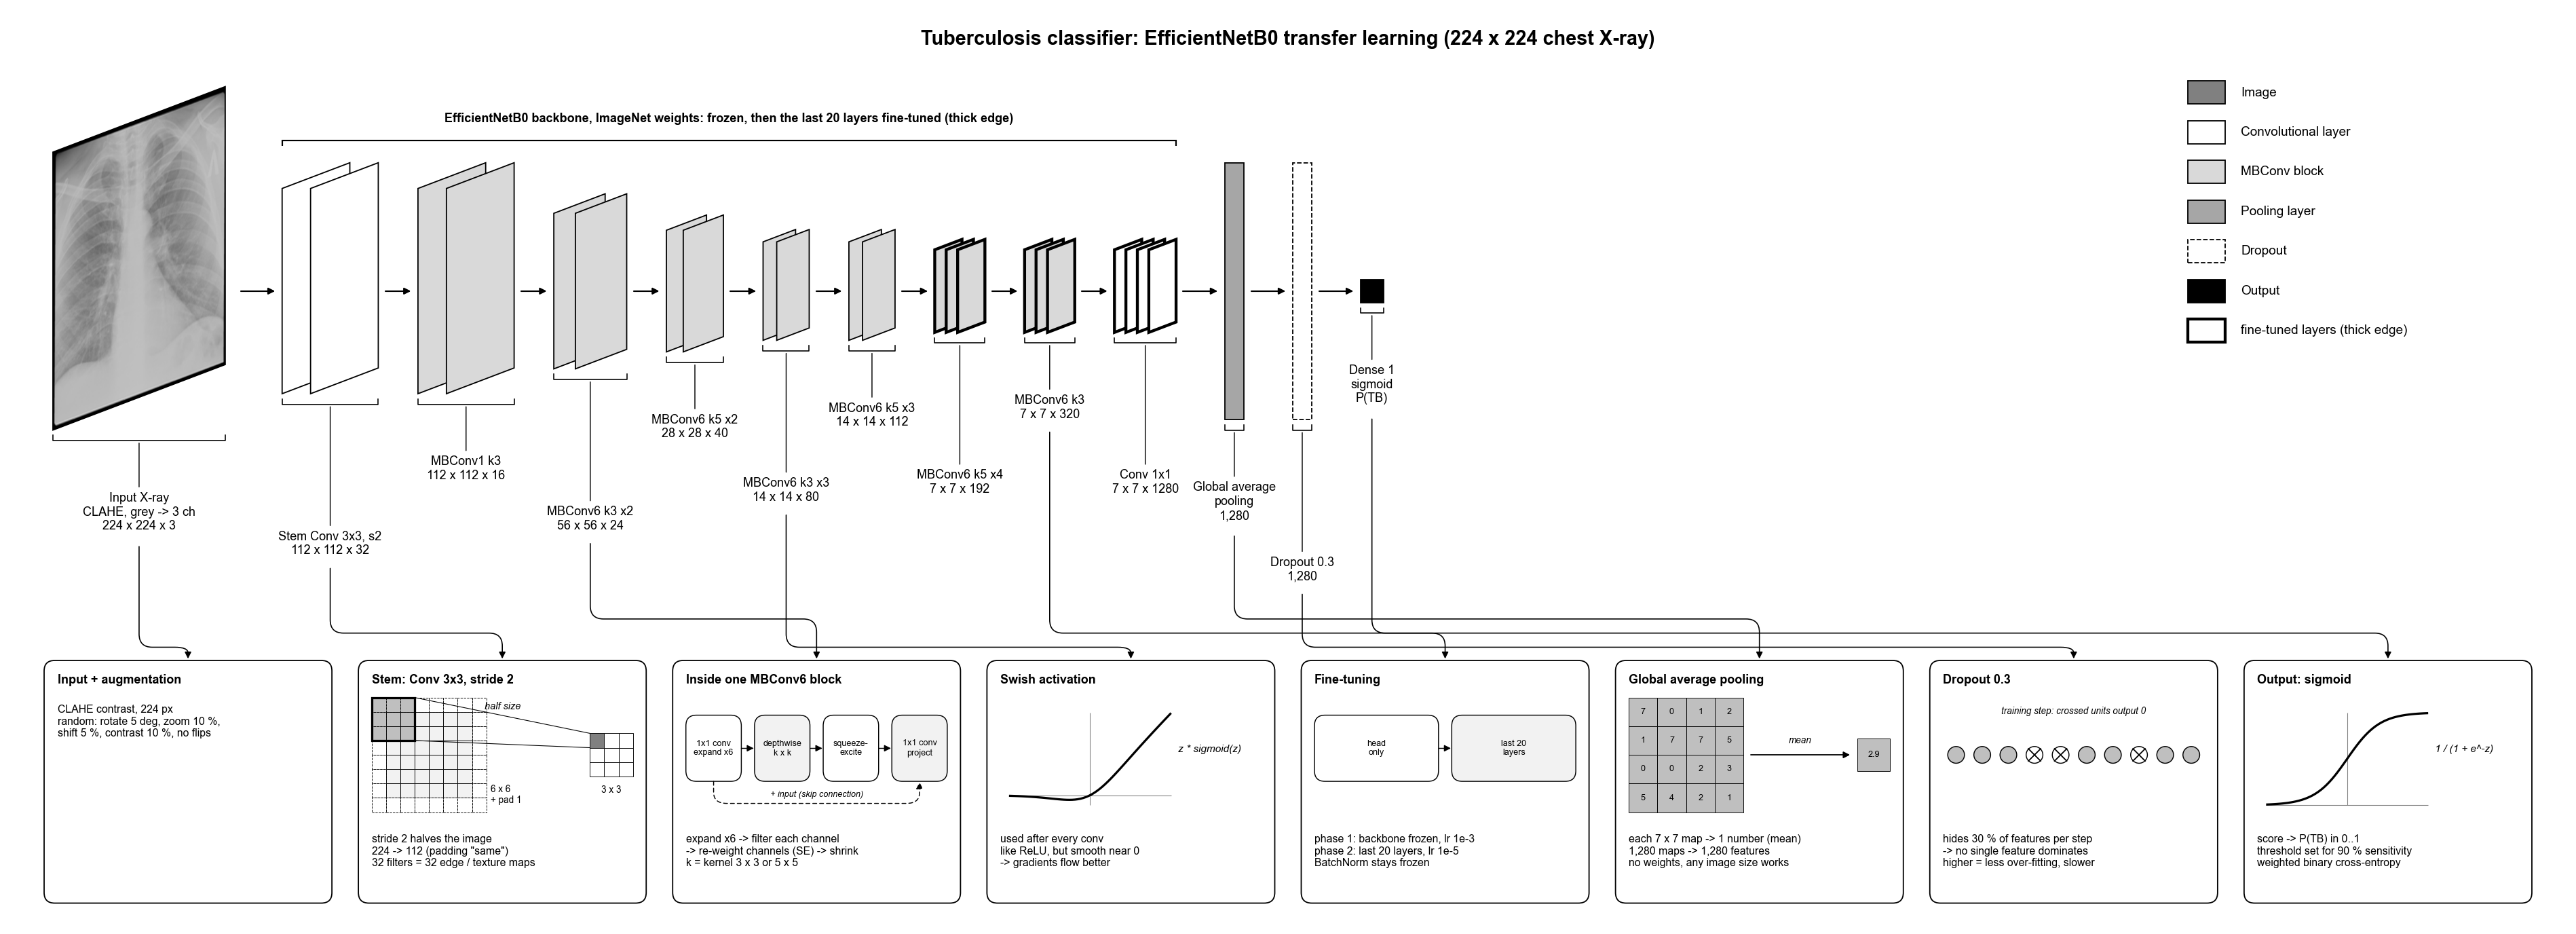

- **Stem** → one 3 × 3 convolution with stride 2: 224 × 224 → 112 × 112
- **MBConv block** → widen the channels (1 × 1 conv, × 6) → filter each channel on its own (depthwise 3 × 3 or 5 × 5) → **squeeze-and-excite** turns each channel up or down → narrow back (1 × 1) → add the input back (skip connection). Cheap, because the expensive filtering is done per channel
- **Stages** → each stage halves the image and adds channels: 112 → 56 → 28 → 14 → 7 pixels, 16 → 320 channels; a final 1 × 1 conv makes 1,280 feature maps
- **Head** → global average pooling (one number per feature map) → dropout 0.3 → one sigmoid unit

$$\text{Swish}(x) = x \cdot \sigma(x)$$
- $x$ → the value coming out of a layer, $\sigma$ → the sigmoid from above
- the activation inside EfficientNet
- In short → big positive values pass almost unchanged and big negative values become about 0, like ReLU, but with a smooth bend around 0 instead of a sharp corner, which helps training

In [ ]:
stage_rows = {}
fine_tuned = {l.name for l in base_model.layers[-FINE_TUNE_LAST_N:]}
for layer in base_model.layers:
    prefix = layer.name.split('_')[0]
    stage = ('stem' if prefix in ('input', 'rescaling', 'normalization', 'stem') else
             'top conv' if prefix == 'top' else f'stage {prefix[5]}')
    row = stage_rows.setdefault(stage, {'stage': stage, 'layers': 0, 'parameters': 0, 'fine-tuned layers': 0})
    row['layers'] += 1
    row['parameters'] += layer.count_params()
    row['fine-tuned layers'] += layer.name in fine_tuned
    row['output shape'] = tuple(layer.output.shape[1:])
stage_table = pd.DataFrame(stage_rows.values())
stage_table['share of parameters'] = (stage_table['parameters'] / stage_table['parameters'].sum()).round(3)

In [ ]:
display(stage_table)
show_block('Backbone', {'layers': len(base_model.layers), 'parameters': f'{base_model.count_params():,}',
                        'head parameters (GAP + dropout + dense)': f'{model.count_params() - base_model.count_params():,}'})

**What the table shows** → the network is heavy where the channels are many, not where the image is big: stage 6 (7 × 7, 192 channels) holds about half of the 4.0 M backbone parameters, while the first stages at 112 × 112 hold almost none. Fine-tuning the last 20 layers changes the end of stage 6, all of stage 7 and the final 1 × 1 conv (the most X-ray-specific, high-level features) and leaves the general edge and texture detectors alone. The new head adds only 1,281 parameters.

**6. Knobs: what they control and what you trade**

| Knob | Here | Controls | Turn it up → | You trade |
|---|---|---|---|---|
| `IMG_SIZE` | 224 | detail the network sees | finer lesions visible | detail vs. memory and time (cost ∝ size²) |
| `ENHANCE` | `'clahe'` | local contrast of the X-ray | (a choice) clearer lung texture | visibility vs. amplified noise |
| `BATCH_SIZE` | 32 | images per update | smoother updates | stability vs. memory, fewer updates |
| `EPOCHS_HEAD` / `EPOCHS_FINE_TUNE` | 10 / 8 | training length (early stopping caps it) | more chances to improve | fit vs. over-fitting and time |
| `FINE_TUNE_LAST_N` | 20 | how much of the backbone may change | more X-ray-specific features | adaptation vs. over-fitting ~2,900 images |
| learning rate | 1e-3 head, 1e-5 fine-tune | step size of each update | faster learning | speed vs. destroying pre-trained features |
| dropout | 0.3 | share of features hidden during training | stronger regularisation | generalisation vs. under-fitting |
| `TARGET_SENSITIVITY` | 0.90 | decision threshold on validation | more TB cases caught | recall vs. more false alarms |

**Rule of thumb** → validation AUC falling while training AUC rises = over-fitting: lower `FINE_TUNE_LAST_N` or the learning rate, or add augmentation.

In [ ]:
print(f'[1/2] Train head · max {EPOCHS_HEAD} epochs')
history_head  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                          callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_head_auc = max(history_head.history['val_auc'])
head_weights  = [(variable, variable.numpy()) for variable in model.weights]
show_block('Outputs', {'best val AUC (head)': f'{best_head_auc:.4f}'})

In [ ]:
print(f'[2/2] Fine-tune last {FINE_TUNE_LAST_N} backbone layers · max {EPOCHS_FINE_TUNE} epochs')
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=make_metrics())
history_ft  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE_TUNE,
                        callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_ft_auc = max(history_ft.history['val_auc'])

if best_ft_auc < best_head_auc:
    for variable, value in head_weights:
        variable.assign(value)
show_block('Outputs', {'best val AUC (head)':      f'{best_head_auc:.4f}',
                       'best val AUC (fine-tune)': f'{best_ft_auc:.4f}',
                       'weights kept':             'fine-tune' if best_ft_auc >= best_head_auc else 'head'})

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ['loss', 'auc', 'recall']):
    train_vals = history_head.history[metric] + history_ft.history[metric]
    val_vals   = history_head.history[f'val_{metric}'] + history_ft.history[f'val_{metric}']
    epochs     = np.arange(1, len(train_vals) + 1)
    ax.plot(epochs, train_vals, label='train')
    ax.plot(epochs, val_vals, label='validation')
    ax.axvline(len(history_head.history[metric]) + 0.5, color='grey', linestyle='--', label='start fine-tuning')
    ax.set(title=metric, xlabel='epoch')
    ax.legend()
plt.tight_layout()
plt.show()

**What to look for** → validation AUC flattening while training AUC keeps rising = **overfitting** (memorising the training X-rays). Early stopping keeps the best validation epoch of each phase.

In [ ]:
"""Optional · Set SAVE_MODEL = True in the top cell to write the model file."""
if SAVE_MODEL:
    model.save(MODEL_FILE)
    print(f'Saved → {MODEL_FILE}')
else:
    print(f'Preview · would save → {MODEL_FILE} · nothing written (SAVE_MODEL = False)')

# [11/13] Evaluation

**Clue** → the best validation AUC is 0.9960: the model ranks X-rays almost perfectly.

**I'm curious** → a ranking is not a decision. A clinic needs one line: above it, send for a sputum test.

**Question** → with the line set for 90% sensitivity on validation, does the untouched test set meet the WHO triage target (≥ 90% sensitivity, ≥ 70% specificity)?

**Let's break it down** → 1) pick the threshold on validation 2) score the test set once 3) count TB caught and false alarms

**Question:** How good is the model as a TB **screening** tool?

**Answer:** On this test set it clears the WHO triage target with room to spare.

| Test set (597 X-rays, 99 TB) | Value |
|---|---|
| ROC-AUC | **0.997** (average precision 0.992) |
| Sensitivity | **93.9%** → 93 of 99 TB cases caught, 6 missed |
| Specificity | **99.8%** → 1 false alarm among 498 normal X-rays |
| Threshold (set on validation) | 0.881 |

**1. Sensitivity and specificity, part by part**

$$\text{Sensitivity} = \frac{TP}{TP + FN} \qquad \text{Specificity} = \frac{TN}{TN + FP}$$

- $TP$ → TB X-rays above the line (flagged) → 93 on test
- $FN$ → TB X-rays below the line (sent home) → 6 → the costly mistake: an untreated patient keeps spreading TB
- $\frac{TP}{TP + FN}$ → **sensitivity**: 93 / 99 = 93.9% → only 99 TB X-rays in test, so every missed case moves it by about 1 point
- $TN$ → normal X-rays below the line (cleared) → 497
- $FP$ → normal X-rays above the line (false alarm) → 1 → costs one sputum test
- $\frac{TN}{TN + FP}$ → **specificity**: 497 / 498 = 99.8%
- both depend on the line: lower it → more TB caught, more false alarms; raise it → the reverse. And both count *what* was flagged, not *why*: with the lungs hidden the same line still flags 49.5% of the TB X-rays ([12/13])
- In short → sensitivity = how many sick people we catch, specificity = how many healthy people we leave alone. Like a smoke alarm: how many real fires it catches, and how much burnt toast it ignores

**2. ROC-AUC, part by part** → the chance that a random TB X-ray scores higher than a random normal one.

$$\text{AUC} = \frac{1}{n_1 n_0} \sum_{i \in \text{TB}} \sum_{j \in \text{normal}} \mathbb{1}\left[p_i > p_j\right]$$

- $(i, j)$ → one TB X-ray paired with one normal X-ray → 99 × 498 = 49,302 pairs on test
- $\mathbb{1}[p_i > p_j]$ → 1 when the TB X-ray gets the higher P(TB): the pair is in the right order
- $\frac{1}{n_1 n_0} \sum \sum$ → the share of pairs in the right order → 0.5 = coin flip, 1.0 = perfect; 0.997 → only about 150 of the 49,302 pairs are the wrong way round
- no threshold inside → it judges the ranking, not the line, so I still need the threshold below
- no class ratio inside → every TB X-ray meets every normal one, so the 1:5 imbalance can't inflate it the way it inflates accuracy (83% for "always normal")
- weak spot → it asks *whether* TB X-rays score higher, not *why*. A model that ranks by hospital scores just as well → [12/13] reuses the same AUC with the lungs hidden to catch that
- In short → put every TB X-ray next to every normal one and count how often the model ranks the TB one higher

**3. Threshold for screening, part by part** → the CNN gives P(TB); the threshold is the line above which I say "send for a sputum test".

$$t^* = \max\big\{\, t \;:\; \text{Sensitivity}_{\text{val}}(t) \ge 0.90 \,\big\}$$

- $t$ → a candidate line on P(TB); every possible line is one point on the ROC curve
- $\text{Sensitivity}_{\text{val}}(t) \ge 0.90$ → keep only lines that catch at least `TARGET_SENSITIVITY` = 90% of the TB X-rays in **validation** → a missed TB case keeps spreading the disease, a false alarm costs one sputum test, so catching TB comes first; 90% is also the WHO triage target
- $\max$ → of those, take the **highest** line → the fewest false alarms that still meet the target
- val, not test → the line is chosen once on validation and reused unchanged on test; tuning it on test would turn the test score into a promise I can't keep
- result → $t^*$ = 0.881, far from the usual 0.5
- weak spot → validation has only about 100 TB X-rays (16.6% of 599), so each one moves the sensitivity by about 1 point and the line can shift from run to run. On test the same line catches 93.9%, so here it held
- In short → walk down from the top of the P(TB) scale until 9 in 10 validation TB cases are above the line, and stop there. Then compare with the WHO target: **≥ 90% sensitivity and ≥ 70% specificity**

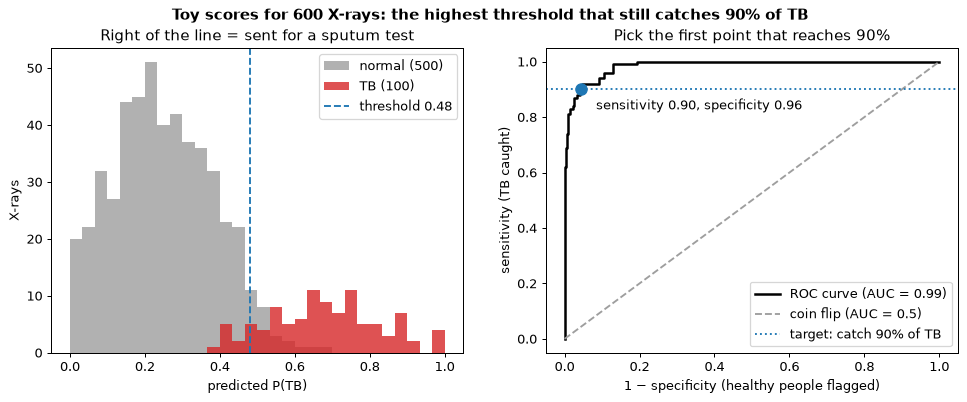

The picture uses toy scores for 600 X-rays; the real curves come after the next cells.

In [ ]:
def predict_proba(model, X):
    return model.predict(make_dataset(X, np.zeros(len(X)), training=False), verbose=0).ravel()


def threshold_for_sensitivity(y, p, target):
    fpr, tpr, thresholds = roc_curve(y, p)
    return thresholds[np.flatnonzero(tpr >= target)[0]]


def screening_metrics(y, p, threshold):
    tn, fp, fn, tp = confusion_matrix(y, (p >= threshold).astype(int), labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y, p), 'average precision': average_precision_score(y, p),
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp), 'TB missed': fn, 'false alarms': fp}


p_val     = predict_proba(model, X_val)
p_te      = predict_proba(model, X_te)
threshold = threshold_for_sensitivity(y_val, p_val, TARGET_SENSITIVITY)
y_pred_te = (p_te >= threshold).astype(int)

display(pd.DataFrame({'validation': screening_metrics(y_val, p_val, threshold),
                      'test':       screening_metrics(y_te, p_te, threshold),
                      'WHO target': {'sensitivity': 0.90, 'specificity': 0.70}}).round(4))
show_block('Outputs', {'threshold (from validation)': f'{threshold:.3f}'})

In [ ]:
display(pd.DataFrame(classification_report(y_te, y_pred_te, target_names=['normal', 'TB'], output_dict=True)).T.round(3))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for name, y_true, p in [('validation', y_val, p_val), ('test', y_te, p_te)]:
    fpr, tpr, _ = roc_curve(y_true, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_true, p):.3f})')
    precision, recall, _ = precision_recall_curve(y_true, p)
    axes[1].plot(recall, precision, label=f'{name} (AP = {average_precision_score(y_true, p):.3f})')
axes[0].plot([0, 1], [0, 1], color='grey', linestyle='--', label='random')
axes[0].add_patch(plt.Rectangle((0, 0.9), 0.3, 0.1, color='green', alpha=0.15, label='WHO target zone'))
axes[0].set(xlabel='1 − specificity', ylabel='Sensitivity', title='ROC curve')
axes[1].axhline(y_te.mean(), color='grey', linestyle='--', label='random (test)')
axes[1].set(xlabel='Recall (sensitivity)', ylabel='Precision', title='Precision-recall curve')
axes[0].legend()
axes[1].legend()

for cls in [0, 1]:
    axes[2].hist(p_te[y_te == cls], bins=25, range=(0, 1), alpha=0.6, color=PALETTE[cls], label=CLASS_NAMES[cls])
axes[2].axvline(threshold, color='blue', linestyle='--', label=f'threshold {threshold:.2f}')
axes[2].set(xlabel='Predicted P(TB)', ylabel='Test images', title='Predicted probabilities (test)', yscale='log')
axes[2].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_te), display_labels=['normal', 'TB']).plot(ax=axes[3], cmap='Greys', colorbar=False)
axes[3].set_title('Test confusion matrix')
axes[3].grid(False)
plt.tight_layout()
plt.show()

# [12/13] Where does the CNN look?

**Clue** → the test score is almost perfect (ROC-AUC 0.997) on a dataset where every Belarus X-ray is TB, every Kaggle / RSNA one is normal, all 308 grayscale files are TB, and the mean images differ most at the corners (up to +60 grey levels).

**I suspect** → part of that 0.997 comes from reading the hospital, not the disease.

**Question** → does the model still find TB with the lungs hidden?

**Let's break it down** → 1) black out the lungs with the mask from [8/13] 2) score again with the same model 3) compare ROC-AUC with the full image and with the lungs alone. A model that still finds TB with the lungs hidden has learned a shortcut.

**Question:** If I black out the lungs, can the model still tell TB from normal?

**Answer:** Yes, and that's the key finding.

| Same model, test set | ROC-AUC | TB still flagged |
|---|---|---|
| full image | 0.997 | 93.9% |
| lungs hidden | **0.981** | 49.5% |
| lungs only | 0.691 | 69.7% |

- with the lungs hidden it still separates the classes almost perfectly → most of the signal can come from outside the lungs (borders, markers, the source fingerprints of [2/13]-[6/13])
- lungs only scores lower, partly because a black background is unlike anything the model trained on
- → the 0.997 is real on this dataset, but part of it is "which hospital". X-rays from a new hospital would likely score lower (next step: a source-held-out test)

→ My suspicion was right: the answer is **partly the hospital**. The ranking survives without the lungs (0.981); only the fixed screening line loses about half of the TB cases (49.5% still flagged), because hiding the lungs shifts the scores.

**Lungs-hidden test in one line** → paint the lungs black and see if the model still says TB. If it does, it's looking somewhere else.

**How, in 3 steps**
1. Take the lung mask from [8/13] for every test X-ray
2. Make two new versions: **lungs only** (everything outside the mask painted black) and **lungs hidden** (the lungs painted black, the rest kept)
3. Score all three versions with the **same** trained model and compare ROC-AUC

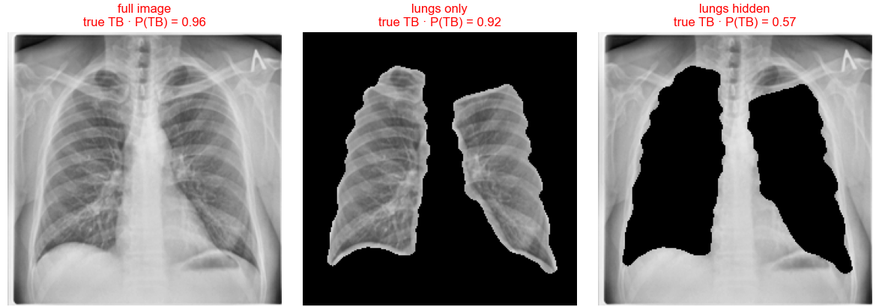

One real TB test X-ray from the Kaggle run: P(TB) drops from 0.96 to 0.57 with the lungs hidden, but stays above 0.5.

**What to look for** → both masked versions look unusual to the model, so some drop is expected either way. The gap between them is the clue: if "lungs hidden" scores far above 0.5, the model finds TB **outside** the lungs.

In [ ]:
m_te      = masks[test_idx]
occlusion = {'full image':   X_te,
             'lungs only':   np.where(m_te, X_te, 0).astype(np.uint8),
             'lungs hidden': np.where(m_te, 0, X_te).astype(np.uint8)}
occ_proba = {name: predict_proba(model, X) for name, X in occlusion.items()}
display(pd.DataFrame({name: {'ROC-AUC':                  roc_auc_score(y_te, p),
                             'mean P(TB) on TB images':  p[y_te == 1].mean(),
                             'mean P(TB) on normal':     p[y_te == 0].mean(),
                             'TB still flagged':         ((p >= threshold) & (y_te == 1)).sum() / (y_te == 1).sum()}
                      for name, p in occ_proba.items()}).T.round(3))

In [ ]:
ids = [*show_rng.choice(np.flatnonzero(y_te == 0), 2, replace=False), *show_rng.choice(np.flatnonzero(y_te == 1), 2, replace=False)]
fig, axes = plt.subplots(len(ids), 3, figsize=(12, 4.25 * len(ids)))
for row, i in enumerate(ids):
    for col, (name, X) in enumerate(occlusion.items()):
        axes[row, col].imshow(X[i], cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'{name}\ntrue {CLASS_NAMES[y_te[i]]} · P(TB) = {occ_proba[name][i]:.2f}', color=PALETTE[y_te[i]])
        axes[row, col].axis('off')
plt.suptitle('The same model on full, lungs-only and lungs-hidden X-rays', fontweight='bold')
plt.tight_layout()
plt.show()

**I'm curious** → if most of the signal can sit outside the lungs, single X-rays should show it too.

**Question:** For single X-rays, which areas push the model towards TB?

**Answer:** Mixed, and it fits the lungs-hidden test.
- true positive → green patches in the left lung, but also a black border strip
- false negative and false positive → the strongest pieces sit on the belly, the edges and the collarbones
- → I use the map as a check on each decision, not as proof that the model reads TB lesions

**LIME in one line** → LIME hides parts of the X-ray and checks how much the CNN's answer changes. The parts that change the answer the most are the parts the CNN is looking at.

**How it works**
1. **Cut the X-ray into pieces (superpixels)** → about 60 pieces of similar brightness (SLIC). LIME hides whole pieces, not single pixels

    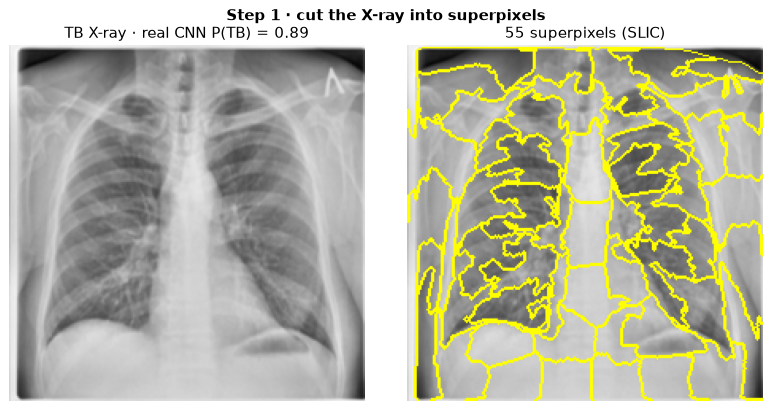
2. **Make altered copies (perturbation)** → LIME makes 300 copies of the X-ray (`LIME_SAMPLES`). In each copy, about half of the pieces are hidden: painted black (`hide_color=0`)
3. **Ask the CNN** → the CNN gives P(TB) for every copy. Hide the pieces it needs → P changes a lot. Hide pieces it ignores → P stays about the same

    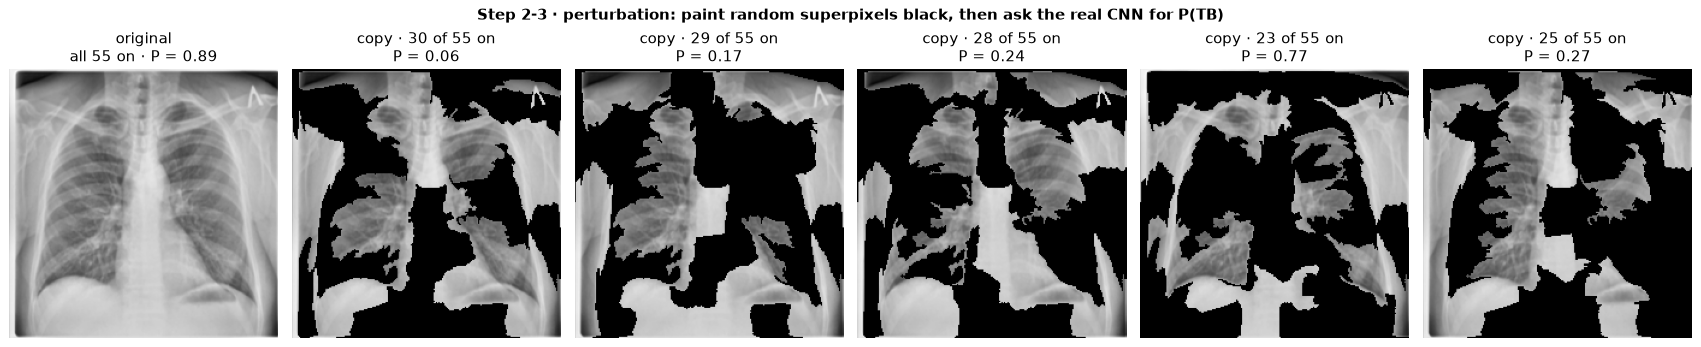
4. **Trust similar copies more** → a copy that still looks almost like the original counts more than a copy with most pieces hidden
5. **Find the important pieces** → LIME fits a simple straight-line formula on the 300 copies

    $$P(\text{TB}) \approx w_0 + \sum_{k} w_k\, z_k$$
    - $z_k$ → 1 if piece $k$ is shown in the copy, 0 if it is hidden
    - $w_k$ → how much P goes up when piece $k$ is shown: big positive $w_k$ = the CNN needs this piece to say "TB"
    - $w_0$ → the P that is left when no special piece is shown
6. **Show the result** → green = pieces that push towards TB, red = pieces that push towards normal

    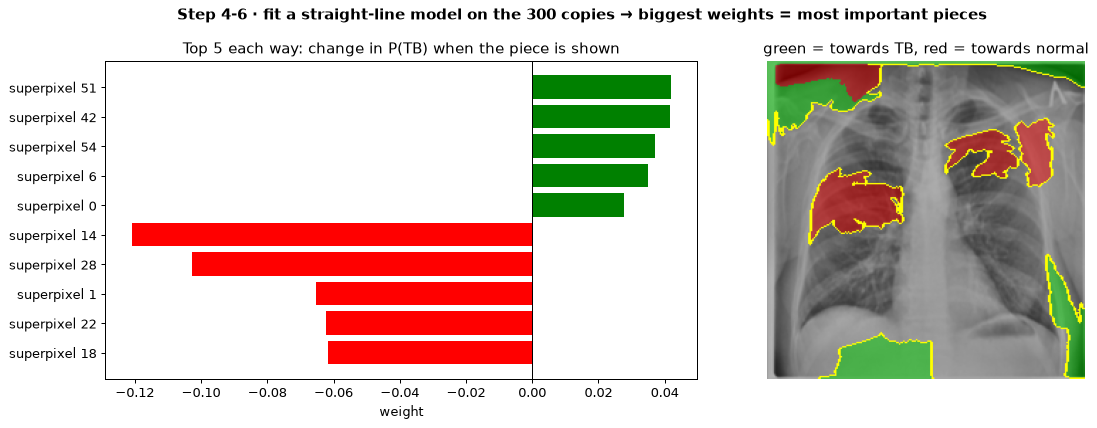

The 3 pictures use the **real trained CNN** on one TB X-ray cropped from this notebook's Kaggle-run figure (P(TB) = 0.89 on the crop, 0.96 on the original file). On this one X-ray the pieces that push towards TB sit on the edges (top strip, bottom, right side), while lung pieces push towards normal: the same story as the lungs-hidden test. It's one example, not a result; the cells below repeat the steps on the test set.

**The weighted linear model behind step 5, part by part**

$$g(z) = w_0 + \sum_{k} w_k z_k \quad \text{fitted by minimising} \quad \sum_{z} \pi_x(z)\,\big(f(z) - g(z)\big)^2 + \lambda \sum_k w_k^2$$

- $z$ → one altered copy written as on/off switches, one per piece (about 60) → 1 = shown, 0 = painted black; the first copy is the original with every switch on, the other 299 are random
- $f(z)$ → the CNN's P(TB) on that copy → weak spot: a copy with black holes looks like nothing the CNN trained on (the same problem as "lungs only" above), so part of a change in P can come from the black paint, not from what was hidden
- $g(z) = w_0 + \sum_k w_k z_k$ → the **straight-line** stand-in for the CNN → each shown piece adds its own fixed amount $w_k$ → assumes the pieces act one by one; if the CNN needs two pieces *together*, a straight line can't say so
- $\big(f(z) - g(z)\big)^2$ → how far the stand-in misses the CNN on one copy, squared as in ordinary least squares
- $\pi_x(z) = \sqrt{\exp(-d^2 / 0.25^2)}$ → **trust similar copies more** (step 4); $d$ = cosine distance between the copy's switches and "all on" → a copy with 90% of the pieces shown counts 0.98, half shown 0.50, 10% shown 0.02 → the line only has to be right *near* this X-ray, which is what "local" means
- $\lambda \sum_k w_k^2$ → a small ridge penalty ($\lambda = 1$, LIME's default) → keeps the ~60 weights from blowing up when 300 copies can't tell them all apart; the maps then show only the 10 pieces with the largest $|w_k|$
- $w_k$ → the answer: big positive → the CNN needs piece $k$ to say TB (green), negative → it pushes towards normal (red)
- In short → LIME fits a simple line that copies the CNN on copies close to this one X-ray, and reads the line's weights as "how much each piece matters". It explains one X-ray, near that X-ray only

In LIME's general notation, $\xi(x) = \arg\min_g \mathcal{L}(f, g, \pi_x) + \Omega(g)$: $\mathcal{L}$ is the weighted sum of squared misses above, $\Omega$ the penalty.

**Colours in the maps below** → green pushes towards TB, red towards normal; yellow = piece borders; cyan line = lung mask.

In [ ]:
def classifier_fn(images):
    p = model.predict(np.asarray(images, dtype=np.float32), batch_size=64, verbose=0).ravel()
    return np.stack([1 - p, p], axis=1)


explainer = lime_image.LimeImageExplainer(random_state=SEED)
segmenter = SegmentationAlgorithm('slic', n_segments=60, compactness=10, start_label=0, random_seed=SEED)

**LIME step by step with the real CNN** → I take the test X-ray the CNN is most sure is TB and show every step: the pieces, 5 altered copies with the CNN's P(TB), the weight of each piece, and the final picture.

In [ ]:
demo_i     = int(np.argmax(np.where(y_te == 1, p_te, -1)))
demo_rgb   = np.repeat(X_te[demo_i][..., None], 3, axis=-1)
demo       = explainer.explain_instance(demo_rgb, classifier_fn, labels=(1,), hide_color=0, segmentation_fn=segmenter,
                                        num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
segments   = demo.segments
n_segments = segments.max() + 1
demo_rng   = np.random.default_rng(SEED)
switches   = demo_rng.integers(0, 2, (5, n_segments))
copies     = np.stack([np.where(z[segments][..., None] == 1, demo_rgb, 0) for z in switches]).astype(np.uint8)
p_copies   = classifier_fn(np.concatenate([demo_rgb[None], copies]))[:, 1]
show_block('Outputs', {'test image':     files_df.loc[test_idx[demo_i], 'file'],
                       'superpixels':    n_segments,
                       'P(TB) original': f'{p_copies[0]:.3f}',
                       'P(TB) copies':   ', '.join(f'{p:.3f}' for p in p_copies[1:])})

In [ ]:
demo_weights        = sorted(demo.local_exp[1], key=lambda t: abs(t[1]), reverse=True)[:10]
demo_ids, demo_vals = zip(*demo_weights)
demo_img, demo_mask = demo.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)

fig   = plt.figure(figsize=(20, 9))
top   = [fig.add_subplot(2, 6, k + 1) for k in range(6)]
bar   = fig.add_subplot(2, 2, 3)
final = fig.add_subplot(2, 2, 4)

top[0].imshow(mark_boundaries(demo_rgb / 255.0, segments))
top[0].set_title(f'1 · {n_segments} superpixels\nP = {p_copies[0]:.2f}')
for ax, z, img, p in zip(top[1:], switches, copies, p_copies[1:]):
    ax.imshow(img)
    ax.set_title(f'2-3 · {z.sum()} of {n_segments} on\nP = {p:.2f}')
for ax in top:
    ax.axis('off')

bar.barh([f'superpixel {k}' for k in demo_ids][::-1], list(demo_vals)[::-1],
         color=['green' if v > 0 else 'red' for v in demo_vals][::-1])
bar.axvline(0, color='black', linewidth=0.8)
bar.set(title='4-5 · weight = change in P(TB) when the piece is shown', xlabel='weight')
final.imshow(mark_boundaries(demo_img / 255.0, demo_mask))
final.contour(m_te[demo_i], colors='cyan', linewidths=1.5)
final.set_title('6 · top 10: green = towards TB, red = towards normal, cyan = lung mask')
final.axis('off')

plt.suptitle('LIME step by step on the test X-ray the CNN is most sure is TB', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
case_masks = {
    'true positive':  (y_te == 1) & (y_pred_te == 1),
    'false negative': (y_te == 1) & (y_pred_te == 0),
    'false positive': (y_te == 0) & (y_pred_te == 1),
    'true negative':  (y_te == 0) & (y_pred_te == 0),
}
rng    = np.random.default_rng(SEED)
chosen = pd.DataFrame([{'case': name, 'test index': int(rng.choice(np.flatnonzero(mask)))}
                       for name, mask in case_masks.items() if mask.any()])
chosen['file']     = files_df.loc[test_idx[chosen['test index']], 'file'].to_numpy()
chosen['true']     = pd.Series(y_te[chosen['test index']]).map(CLASS_NAMES)
chosen['P(TB)']    = p_te[chosen['test index']].round(3)

empty_cases = [name for name, mask in case_masks.items() if not mask.any()]
if empty_cases:
    print('(!) No test images for: ' + ', '.join(empty_cases))
display(chosen)

In [ ]:
fig, axes = plt.subplots(len(chosen), 3, figsize=(13, 4.4 * len(chosen)), squeeze=False)
for row, (_, case) in enumerate(chosen.iterrows()):
    print(f"[{row + 1}/{len(chosen)}] LIME · {case['case']} · {case['file']}")
    if case['case'] == 'false negative':
        print('    (!) a TB case the model sent home')
    i           = case['test index']
    rgb         = np.repeat(X_te[i][..., None], 3, axis=-1)
    explanation = explainer.explain_instance(rgb, classifier_fn, labels=(1,), hide_color=0, segmentation_fn=segmenter,
                                             num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
    img_pos, mask_pos   = explanation.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
    img_both, mask_both = explanation.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)

    axes[row, 0].imshow(X_te[i], cmap='gray')
    axes[row, 0].set_title(f"{case['case']}\ntrue = {case['true']}, P(TB) = {case['P(TB)']:.2f}")
    axes[row, 1].imshow(mark_boundaries(img_pos / 255.0, mask_pos))
    axes[row, 1].set_title('Top 5 superpixels supporting "TB"')
    axes[row, 2].imshow(mark_boundaries(img_both / 255.0, mask_both))
    axes[row, 2].set_title('Top 10: green = towards TB, red = towards normal')
    for ax in axes[row]:
        ax.contour(m_te[i], colors='cyan', linewidths=1.5)
        ax.axis('off')

plt.suptitle('LIME explanations on the test set', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# [13/13] Gradio app

**Aim** → put the trained CNN in a small screening app: upload an X-ray, get P(TB), a decision at the screening threshold and a LIME map.

**How it works**
1. **Same preparation as training** → grayscale, resized to `IMG_SIZE` × `IMG_SIZE`, then `ENHANCE`
2. **Score** → the CNN gives P(TB)
3. **Decide** → P(TB) at or above the validation threshold from [11/13] → "refer for a sputum test", below → "routine care"
4. **Explain** → the same LIME map as in [12/13], with the lung outline in cyan

**Run it** → set `LAUNCH_APP = True` in the top cell; Kaggle prints a temporary public link. With `SAVE_MODEL = True` the model and `settings.json` (image size, enhancement, threshold) are written too, so the standalone `app.py` can run the same app on your own computer.

It's a triage aid that sorts X-rays for a doctor, not a diagnosis.

In [ ]:
def screen(image):
    gray = image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    x    = ENHANCERS[ENHANCE](cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    rgb  = np.repeat(x[..., None], 3, axis=-1)
    p    = float(classifier_fn(rgb[None])[0, 1])
    text = (f'### {"Possible TB → refer for a sputum test" if p >= threshold else "No TB pattern found → routine care"}\n'
            f'P(TB) = **{p:.3f}** · threshold {threshold:.3f}')
    explanation = explainer.explain_instance(rgb, classifier_fn, labels=(1,), hide_color=0, segmentation_fn=segmenter,
                                             num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
    img, mask = explanation.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(mark_boundaries(img / 255.0, mask))
    ax.contour(lung_mask(x), colors='cyan', linewidths=1.2)
    ax.set_title('LIME: green → TB, red → normal')
    ax.axis('off')
    return {'Tuberculosis': p, 'Normal': 1 - p}, text, fig


if SAVE_MODEL:
    with open(SETTINGS_FILE, 'w') as f:
        json.dump({'img_size': IMG_SIZE, 'enhance': ENHANCE, 'threshold': float(threshold)}, f)
    print(f'Saved → {SETTINGS_FILE}')

if LAUNCH_APP:
    import gradio as gr
    with gr.Blocks(title='Tuberculosis X-ray screening') as demo:
        gr.Markdown('# Tuberculosis Chest X-ray Screening')
        with gr.Row():
            inp = gr.Image(type='numpy', label='Chest X-ray')
            with gr.Column():
                prob, text, plot = gr.Label(num_top_classes=2), gr.Markdown(), gr.Plot()
        gr.Button('Screen', variant='primary').click(screen, inputs=inp, outputs=[prob, text, plot])
        gr.Examples([[p] for p in files_df.loc[test_idx[:6], 'path']], inputs=inp)
    demo.launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Next steps**
- **Source-held-out test** → train on some collections and test on another; the only honest answer to "does it work in a new hospital?"
- **Learned lung segmentation** → a U-Net trained on the Montgomery / Shenzhen lung masks, then train the classifier on lungs only
- **Grad-CAM** → a second explanation method that reads the CNN's own feature maps, to cross-check LIME
- **More TB images** → the 2,800 extra TB X-rays from the NIAID portal (data agreement required) would ease the 1:5 imbalance
- **Calibration** → check that P(TB) = 0.8 really means 8 in 10 such X-rays show TB